In [2]:

from pathlib import Path
from importlib.util import find_spec
import hashlib
import pandas as pd
import sys

input_root = Path("/kaggle/input")

assert input_root.is_dir()

print("ATTACHED KAGGLE DATASETS")

for folder in sorted(input_root.iterdir()):
    print(folder)

manifest_files = sorted(
    input_root.rglob("D1_split_manifest.csv")
)

print("\nD1 MANIFEST CANDIDATES")

for path in manifest_files:
    print(path)

assert len(manifest_files) == 1, (
    "Exactly one D1 split manifest must be attached."
)

d1_manifest_path = manifest_files[0]

d1_manifest = pd.read_csv(
    d1_manifest_path
)

required_columns = {
    "rel_path",
    "class_id",
    "split"
}

assert required_columns.issubset(
    d1_manifest.columns
)

expected_counts = {
    "train": 1156,
    "val": 247,
    "test": 248
}

actual_counts = (
    d1_manifest["split"].value_counts().to_dict()
)

assert len(d1_manifest) == 1651
assert actual_counts == expected_counts
assert d1_manifest["rel_path"].is_unique
assert d1_manifest["rel_path"].notna().all()
assert set(d1_manifest["class_id"]) == set(range(8))

manifest_hash = hashlib.sha256(
    d1_manifest_path.read_bytes()
).hexdigest()

print("\nD1 DATASET VERIFICATION")
print("Retained images:", len(d1_manifest))
print("Training images:", actual_counts["train"])
print("Validation images:", actual_counts["val"])
print("Test images:", actual_counts["test"])
print("Classes:", d1_manifest["class_id"].nunique())
print("Manifest SHA256:", manifest_hash)

print("\nSAMPLE IMAGE PATHS")

for path in d1_manifest["rel_path"].head(3):
    print(path)

print("\nSOFTWARE ENVIRONMENT")
print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print(
    "TensorFlow installed:",
    find_spec("tensorflow") is not None
)

print("\nPAPER 1 D1 INITIAL VERIFICATION: PASSED")


ATTACHED KAGGLE DATASETS
/kaggle/input/datasets

D1 MANIFEST CANDIDATES
/kaggle/input/datasets/nayebul0/assignment02-verified-train-val-test-splits/D1_split_manifest.csv

D1 DATASET VERIFICATION
Retained images: 1651
Training images: 1156
Validation images: 247
Test images: 248
Classes: 8
Manifest SHA256: 3b756d0a4f0326a5e5123284aa884f23fe604d4ace6c56477491acd80ae728d0

SAMPLE IMAGE PATHS
Bacterial Leaf Blight/Bacterial_leaf_Blight  (1).jpg
Bacterial Leaf Blight/Bacterial_leaf_Blight  (10).jpg
Bacterial Leaf Blight/Bacterial_leaf_Blight  (101).jpg

SOFTWARE ENVIRONMENT
Python: 3.13.16
Pandas: 2.3.3
TensorFlow installed: True

PAPER 1 D1 INITIAL VERIFICATION: PASSED


In [3]:

from pathlib import Path
from PIL import Image
import tensorflow as tf
import keras

sample_rel = Path(
    str(d1_manifest.iloc[0]["rel_path"])
)

matches = sorted(
    Path("/kaggle/input").rglob(sample_rel.name)
)

candidate_roots = []

for match in matches:
    if match.parent.name != sample_rel.parent.name:
        continue

    root = match.parent.parent

    present = sum(
        (root / str(rel_path)).is_file()
        for rel_path in d1_manifest["rel_path"]
    )

    if present == len(d1_manifest):
        candidate_roots.append(root)

candidate_roots = list(
    dict.fromkeys(candidate_roots)
)

print("Matching D1 image roots:")
for root in candidate_roots:
    print(root)

assert len(candidate_roots) == 1, (
    "Expected one complete D1 image root. "
    "Inspect the attached datasets."
)

D1_ROOT = candidate_roots[0]

missing = [
    str(rel_path)
    for rel_path in d1_manifest["rel_path"]
    if not (D1_ROOT / str(rel_path)).is_file()
]

assert len(missing) == 0

sample_indices = [
    0,
    len(d1_manifest) // 2,
    len(d1_manifest) - 1
]

for index in sample_indices:
    image_path = (
        D1_ROOT /
        str(d1_manifest.iloc[index]["rel_path"])
    )

    with Image.open(image_path) as image:
        image.load()
        assert image.width > 0
        assert image.height > 0

print("\nDATASET IMAGE VERIFICATION")
print("D1 image root:", D1_ROOT)
print("Images found:", len(d1_manifest))
print("Missing images:", len(missing))
print("Sample image decoding: PASSED")

print("\nTENSORFLOW ENVIRONMENT")
print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)
print("Physical GPUs:", tf.config.list_physical_devices("GPU"))

print("\nPAPER 1 D1 IMAGE AND ENVIRONMENT: PASSED")


Matching D1 image roots:
/kaggle/input/datasets/nayebul0/assignment02-d1-original-rice-leaf-1701/Original Images

DATASET IMAGE VERIFICATION
D1 image root: /kaggle/input/datasets/nayebul0/assignment02-d1-original-rice-leaf-1701/Original Images
Images found: 1651
Missing images: 0
Sample image decoding: PASSED

TENSORFLOW ENVIRONMENT
TensorFlow version: 2.21.0
Keras version: 3.13.2
Physical GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

PAPER 1 D1 IMAGE AND ENVIRONMENT: PASSED


In [4]:

import numpy as np
import tensorflow as tf
import keras

from keras import layers

SEED = 2026
NUM_CLASSES = 8
INPUT_SIZE = (224, 224)

keras.utils.set_random_seed(SEED)

keras.backend.clear_session()

backbone = keras.applications.MobileNetV3Large(
    input_shape=(224, 224, 3),
    alpha=1.0,
    minimalistic=False,
    include_top=False,
    weights="imagenet",
    include_preprocessing=True
)

backbone.trainable = False

inputs = keras.Input(
    shape=(224, 224, 3),
    name="rice_leaf_input"
)

features = backbone(
    inputs,
    training=False
)

x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(features)

x = layers.Dense(
    128,
    activation="relu",
    name="custom_dense_128"
)(x)

x = layers.Dropout(
    0.5,
    name="custom_dropout"
)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="rice_disease_predictions"
)(x)

model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="Paper1_MobileNetV3Large_D1"
)

total_params = model.count_params()

trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in model.trainable_weights
)

frozen_params = sum(
    int(np.prod(weight.shape))
    for weight in model.non_trainable_weights
)

assert model.input_shape == (None, 224, 224, 3)
assert model.output_shape == (None, 8)

assert backbone.output_shape == (
    None, 7, 7, 960
)

assert backbone.trainable is False

assert all(
    not layer.trainable
    for layer in backbone.layers
)

assert model.get_layer(
    "custom_dense_128"
).units == 128

assert model.get_layer(
    "custom_dropout"
).rate == 0.5

assert model.get_layer(
    "rice_disease_predictions"
).units == 8

assert total_params == trainable_params + frozen_params

assert total_params == 3120392
assert trainable_params == 124040
assert frozen_params == 2996352

sample_input = tf.zeros(
    (1, 224, 224, 3),
    dtype=tf.float32
)

sample_output = model(
    sample_input,
    training=False
)

assert tuple(sample_output.shape) == (1, 8)

assert bool(
    tf.reduce_all(
        tf.math.is_finite(sample_output)
    )
)

assert np.allclose(
    tf.reduce_sum(
        sample_output,
        axis=1
    ).numpy(),
    1.0,
    atol=1e-5
)

print("Model:", model.name)
print("Backbone:", backbone.name)
print("Backbone layers:", len(backbone.layers))
print("Backbone feature output:", backbone.output_shape)
print("Input shape:", model.input_shape)
print("Classification output:", model.output_shape)

print("\nMODEL PARAMETERS")
print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("Frozen parameters:", frozen_params)

print("\nARCHITECTURE CHECKS")
print("ImageNet weights: LOADED")
print("Backbone frozen:", not backbone.trainable)
print("Custom dense units: 128")
print("Dropout rate: 0.5")
print("Output classes:", NUM_CLASSES)
print("Forward pass: PASSED")
print("Softmax probability sum: PASSED")

print("\nPAPER 1 D1 ARCHITECTURE: PASSED")


12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Model: Paper1_MobileNetV3Large_D1
Backbone: MobileNetV3Large
Backbone layers: 187
Backbone feature output: (None, 7, 7, 960)
Input shape: (None, 224, 224, 3)
Classification output: (None, 8)

MODEL PARAMETERS
Total parameters: 3120392
Trainable parameters: 124040
Frozen parameters: 2996352

ARCHITECTURE CHECKS
ImageNet weights: LOADED
Backbone frozen: True
Custom dense units: 128
Dropout rate: 0.5
Output classes: 8
Forward pass: PASSED
Softmax probability sum: PASSED

PAPER 1 D1 ARCHITECTURE: PASSED


In [5]:

import numpy as np
import tensorflow as tf
import keras

from pathlib import Path

SEED = 2026

keras.utils.set_random_seed(SEED)

paper1_augmentation = keras.Sequential(
    [
        keras.layers.RandomRotation(
            0.05,
            fill_mode="reflect",
            seed=SEED + 1
        ),
        keras.layers.RandomFlip(
            "horizontal",
            seed=SEED + 2
        ),
        keras.layers.RandomZoom(
            0.1,
            fill_mode="reflect",
            seed=SEED + 3
        ),
        keras.layers.RandomBrightness(
            factor=0.1,
            value_range=(0.0, 1.0),
            seed=SEED + 4
        ),
        keras.layers.GaussianNoise(
            stddev=0.1,
            seed=SEED + 5
        )
    ],
    name="paper1_training_augmentation"
)


def paper1_load_image(rel_path):
    path = D1_ROOT / str(rel_path)

    image_bytes = tf.io.read_file(str(path))

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(
        tf.cast(image, tf.float32),
        [224, 224],
        method="bilinear"
    )

    return tf.clip_by_value(
        image,
        0.0,
        255.0
    )


def paper1_transform(image, training=False):
    image = tf.cast(image, tf.float32)

    if training:
        normalized = image / 255.0

        normalized = paper1_augmentation(
            tf.expand_dims(normalized, axis=0),
            training=True
        )[0]

        image = tf.clip_by_value(
            normalized,
            0.0,
            1.0
        ) * 255.0

    return image


train_row = d1_manifest[
    d1_manifest["split"] == "train"
].iloc[0]

val_row = d1_manifest[
    d1_manifest["split"] == "val"
].iloc[0]

train_original = paper1_load_image(
    train_row["rel_path"]
)

train_augmented = paper1_transform(
    train_original,
    training=True
)

val_original = paper1_load_image(
    val_row["rel_path"]
)

val_first = paper1_transform(
    val_original,
    training=False
)

val_second = paper1_transform(
    val_original,
    training=False
)

assert tuple(train_original.shape) == (224, 224, 3)
assert tuple(train_augmented.shape) == (224, 224, 3)
assert tuple(val_first.shape) == (224, 224, 3)

assert train_augmented.dtype == tf.float32
assert val_first.dtype == tf.float32

assert bool(
    tf.reduce_all(
        tf.math.is_finite(train_augmented)
    )
)

assert bool(
    tf.reduce_all(
        tf.math.is_finite(val_first)
    )
)

assert float(
    tf.reduce_min(train_augmented).numpy()
) >= 0.0

assert float(
    tf.reduce_max(train_augmented).numpy()
) <= 255.0

assert float(
    tf.reduce_min(val_first).numpy()
) >= 0.0

assert float(
    tf.reduce_max(val_first).numpy()
) <= 255.0

validation_deterministic = np.array_equal(
    val_first.numpy(),
    val_second.numpy()
)

training_image_changed = not np.array_equal(
    train_original.numpy(),
    train_augmented.numpy()
)

assert validation_deterministic
assert training_image_changed

real_image_output = model(
    tf.expand_dims(val_first, axis=0),
    training=False
)

assert tuple(real_image_output.shape) == (1, 8)

assert np.allclose(
    np.sum(real_image_output.numpy(), axis=1),
    1.0,
    atol=1e-5
)

print("Dataset: D1")
print("Input size:", tuple(train_original.shape))
print("Training augmentation:", training_image_changed)
print("Validation deterministic:", validation_deterministic)

print("\nPREPROCESSING")
print("Training image dtype:", train_augmented.dtype)
print(
    "Training pixel range:",
    round(float(tf.reduce_min(train_augmented)), 3),
    round(float(tf.reduce_max(train_augmented)), 3)
)

print(
    "Validation pixel range:",
    round(float(tf.reduce_min(val_first)), 3),
    round(float(tf.reduce_max(val_first)), 3)
)

print("\nMODEL COMPATIBILITY")
print("Expected input range: 0–255")
print("Output classes:", real_image_output.shape[-1])
print("Real-image forward pass: PASSED")
print("Softmax probability sum: PASSED")

print("\nPAPER 1 D1 PREPROCESSING VERIFICATION: PASSED")


Dataset: D1
Input size: (224, 224, 3)
Training augmentation: True
Validation deterministic: True

PREPROCESSING
Training image dtype: <dtype: 'float32'>
Training pixel range: 0.0 255.0
Validation pixel range: 0.0 255.0

MODEL COMPATIBILITY
Expected input range: 0–255
Output classes: 8
Real-image forward pass: PASSED
Softmax probability sum: PASSED

PAPER 1 D1 PREPROCESSING VERIFICATION: PASSED


In [6]:

import hashlib
import numpy as np
import tensorflow as tf

SEED = 2026
BATCH_SIZE = 32

expected_manifest_hash = (
    "3b756d0a4f0326a5e5123284aa884f23"
    "fe604d4ace6c56477491acd80ae728d0"
)

actual_manifest_hash = hashlib.sha256(
    d1_manifest_path.read_bytes()
).hexdigest()

assert actual_manifest_hash == expected_manifest_hash

d1_train_rows = d1_manifest[
    d1_manifest["split"] == "train"
].sort_values("rel_path").reset_index(drop=True)

d1_val_rows = d1_manifest[
    d1_manifest["split"] == "val"
].sort_values("rel_path").reset_index(drop=True)

assert len(d1_train_rows) == 1156
assert len(d1_val_rows) == 247

assert set(d1_train_rows["class_id"]) == set(range(8))
assert set(d1_val_rows["class_id"]) == set(range(8))

assert not (
    set(d1_train_rows["rel_path"])
    & set(d1_val_rows["rel_path"])
)


def paper1_decode_sample(path, label):
    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image = tf.ensure_shape(
        image,
        [None, None, 3]
    )

    image = tf.image.resize(
        tf.cast(image, tf.float32),
        [224, 224],
        method="bilinear"
    )

    image = tf.clip_by_value(
        image,
        0.0,
        255.0
    )

    return image, label


def paper1_augment_batch(images, labels):
    normalized = images / 255.0

    normalized = paper1_augmentation(
        normalized,
        training=True
    )

    images = tf.clip_by_value(
        normalized,
        0.0,
        1.0
    ) * 255.0

    return images, labels


def build_paper1_dataset(rows, training):
    paths = [
        str(D1_ROOT / str(rel_path))
        for rel_path in rows["rel_path"]
    ]

    labels = rows["class_id"].to_numpy(
        dtype=np.int32
    )

    assert all(
        (D1_ROOT / str(rel_path)).is_file()
        for rel_path in rows["rel_path"]
    )

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(rows),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        paper1_decode_sample,
        num_parallel_calls=1
    )

    dataset = dataset.batch(
        BATCH_SIZE,
        drop_remainder=False
    )

    if training:
        dataset = dataset.map(
            paper1_augment_batch,
            num_parallel_calls=1
        )

    options = tf.data.Options()
    options.experimental_deterministic = True

    dataset = dataset.with_options(options)
    dataset = dataset.prefetch(1)

    return dataset


d1_train_loader = build_paper1_dataset(
    d1_train_rows,
    training=True
)

d1_val_loader = build_paper1_dataset(
    d1_val_rows,
    training=False
)

assert int(
    tf.data.experimental.cardinality(
        d1_train_loader
    ).numpy()
) == 37

assert int(
    tf.data.experimental.cardinality(
        d1_val_loader
    ).numpy()
) == 8

train_images, train_labels = next(
    iter(d1_train_loader)
)

val_images, val_labels = next(
    iter(d1_val_loader)
)

assert tuple(train_images.shape) == (
    32, 224, 224, 3
)

assert tuple(val_images.shape) == (
    32, 224, 224, 3
)

assert train_images.dtype == tf.float32
assert val_images.dtype == tf.float32

assert train_labels.dtype == tf.int32
assert val_labels.dtype == tf.int32

assert bool(
    tf.reduce_all(tf.math.is_finite(train_images))
)

assert bool(
    tf.reduce_all(tf.math.is_finite(val_images))
)

assert bool(
    tf.reduce_all(
        (train_images >= 0.0) &
        (train_images <= 255.0)
    )
)

assert bool(
    tf.reduce_all(
        (val_images >= 0.0) &
        (val_images <= 255.0)
    )
)

val_images_again, val_labels_again = next(
    iter(d1_val_loader)
)

assert np.array_equal(
    val_images.numpy(),
    val_images_again.numpy()
)

assert np.array_equal(
    val_labels.numpy(),
    val_labels_again.numpy()
)

print("Dataset: D1")
print("Training images:", len(d1_train_rows))
print("Validation images:", len(d1_val_rows))
print("Test images reserved:", 248)

print("\nTraining batches:", 37)
print("Validation batches:", 8)

print("Training batch:", tuple(train_images.shape))
print("Validation batch:", tuple(val_images.shape))

print("\nTraining shuffle: ENABLED")
print("Training augmentation: ENABLED")
print("Validation augmentation: DISABLED")
print("Validation deterministic: True")

print("Training labels:", sorted(
    d1_train_rows["class_id"].unique().tolist()
))

print("Validation labels:", sorted(
    d1_val_rows["class_id"].unique().tolist()
))

print("\nPAPER 1 D1 DATA PIPELINE: PASSED")


Dataset: D1
Training images: 1156
Validation images: 247
Test images reserved: 248

Training batches: 37
Validation batches: 8
Training batch: (32, 224, 224, 3)
Validation batch: (32, 224, 224, 3)

Training shuffle: ENABLED
Training augmentation: ENABLED
Validation augmentation: DISABLED
Validation deterministic: True
Training labels: [0, 1, 2, 3, 4, 5, 6, 7]
Validation labels: [0, 1, 2, 3, 4, 5, 6, 7]

PAPER 1 D1 DATA PIPELINE: PASSED


In [7]:

from pathlib import Path
import json
import numpy as np
import keras

SEED = 2026
STAGE1_MAX_EPOCHS = 30
STAGE1_LR = 0.0001

RUN_DIR = Path(
    "/kaggle/working/Assignment02_Experiment3_D1"
)

RUN_DIR.mkdir(
    parents=True,
    exist_ok=True
)

STAGE1_BEST_PATH = (
    RUN_DIR / "stage1_best.keras"
)

STAGE1_HISTORY_PATH = (
    RUN_DIR / "stage1_history.csv"
)

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=STAGE1_LR
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

stage1_callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(STAGE1_BEST_PATH),
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=5,
        restore_best_weights=False,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=3,
        verbose=1
    ),
    keras.callbacks.CSVLogger(
        filename=str(STAGE1_HISTORY_PATH)
    ),
    keras.callbacks.TerminateOnNaN()
]

trainable_params = sum(
    int(np.prod(w.shape))
    for w in model.trainable_weights
)

frozen_params = sum(
    int(np.prod(w.shape))
    for w in model.non_trainable_weights
)

assert backbone.trainable is False
assert all(not layer.trainable for layer in backbone.layers)

assert trainable_params == 124040
assert frozen_params == 2996352

assert isinstance(
    model.optimizer,
    keras.optimizers.Adam
)

assert isinstance(
    model.loss,
    keras.losses.SparseCategoricalCrossentropy
)

assert np.isclose(
    float(model.optimizer.learning_rate.numpy()),
    STAGE1_LR
)

assert stage1_callbacks[0].monitor == "val_accuracy"
assert stage1_callbacks[1].monitor == "val_loss"
assert stage1_callbacks[1].patience == 5
assert stage1_callbacks[2].patience == 3
assert stage1_callbacks[2].factor == 0.5

assert BATCH_SIZE == 32
assert STAGE1_MAX_EPOCHS == 30

stage1_config = {
    "experiment": "Assignment02_Experiment3_D1",
    "paper": "Paper 1",
    "architecture": "MobileNetV3-Large",
    "dataset": "D1",
    "manifest_sha256": actual_manifest_hash,
    "seed": SEED,
    "num_classes": 8,
    "input_size": [224, 224, 3],
    "batch_size": BATCH_SIZE,
    "stage": "frozen_backbone",
    "max_epochs": STAGE1_MAX_EPOCHS,
    "optimizer": "Adam",
    "initial_learning_rate": STAGE1_LR,
    "loss": "SparseCategoricalCrossentropy",
    "checkpoint_monitor": "val_accuracy",
    "early_stopping_monitor": "val_loss",
    "early_stopping_patience": 5,
    "reduce_lr_factor": 0.5,
    "reduce_lr_patience": 3,
    "tensorflow_version": __import__("tensorflow").__version__,
    "keras_version": keras.__version__,
    "trainable_parameters": trainable_params,
    "frozen_parameters": frozen_params
}

config_path = RUN_DIR / "stage1_config.json"

with config_path.open("w") as f:
    json.dump(
        stage1_config,
        f,
        indent=2
    )

print("EXPERIMENT:", model.name)

print("\nSTAGE 1 CONFIGURATION")
print("Backbone frozen:", not backbone.trainable)
print("Optimizer:", type(model.optimizer).__name__)
print("Learning rate:", STAGE1_LR)
print("Maximum epochs:", STAGE1_MAX_EPOCHS)
print("Batch size:", BATCH_SIZE)

print("\nMODEL PARAMETERS")
print("Trainable:", trainable_params)
print("Frozen:", frozen_params)

print("\nCALLBACKS")
print("Checkpoint monitor:", stage1_callbacks[0].monitor)
print("Early stopping monitor:", stage1_callbacks[1].monitor)
print("Early stopping patience:", stage1_callbacks[1].patience)
print("LR reduction factor:", stage1_callbacks[2].factor)
print("LR reduction patience:", stage1_callbacks[2].patience)

print("\nCONFIG FILE:", config_path)
print("Training started: NO")

print("\nPAPER 1 D1 STAGE 1 CONFIGURATION: PASSED")


EXPERIMENT: Paper1_MobileNetV3Large_D1

STAGE 1 CONFIGURATION
Backbone frozen: True
Optimizer: Adam
Learning rate: 0.0001
Maximum epochs: 30
Batch size: 32

MODEL PARAMETERS
Trainable: 124040
Frozen: 2996352

CALLBACKS
Checkpoint monitor: val_accuracy
Early stopping monitor: val_loss
Early stopping patience: 5
LR reduction factor: 0.5
LR reduction patience: 3

CONFIG FILE: /kaggle/working/Assignment02_Experiment3_D1/stage1_config.json
Training started: NO

PAPER 1 D1 STAGE 1 CONFIGURATION: PASSED


In [8]:

import tensorflow as tf
import keras
import numpy as np

print("TENSORFLOW GPU VERIFICATION")

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

gpus = tf.config.list_physical_devices("GPU")

print("\nAVAILABLE GPUs:")

for gpu in gpus:
    print(gpu)

assert len(gpus) >= 1, (
    "No GPU detected. Check Kaggle accelerator settings."
)

with tf.device("/GPU:0"):
    a = tf.ones((512, 512), dtype=tf.float32)
    b = tf.ones((512, 512), dtype=tf.float32)
    result = tf.matmul(a, b)

assert bool(
    tf.reduce_all(tf.math.is_finite(result))
)

assert "GPU" in result.device.upper(), (
    "Matrix multiplication was not placed on GPU."
)

print("\nGPU COMPUTATION")
print("Result shape:", result.shape)
print("Execution device:", result.device)

print("\nMODEL VERIFICATION")
print("Model:", model.name)
print("Backbone frozen:", not backbone.trainable)

assert backbone.trainable is False

assert np.isclose(
    float(model.optimizer.learning_rate.numpy()),
    0.0001
)

print("Stage 1 optimizer: READY")
print("Training started: NO")

print("\nPAPER 1 D1 GPU VERIFICATION: PASSED")


TENSORFLOW GPU VERIFICATION
TensorFlow: 2.21.0
Keras: 3.13.2

AVAILABLE GPUs:
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')

GPU COMPUTATION
Result shape: (512, 512)
Execution device: /job:localhost/replica:0/task:0/device:GPU:0

MODEL VERIFICATION
Model: Paper1_MobileNetV3Large_D1
Backbone frozen: True
Stage 1 optimizer: READY
Training started: NO

PAPER 1 D1 GPU VERIFICATION: PASSED


In [9]:

import numpy as np
import tensorflow as tf

required_variables = [
    "model",
    "backbone",
    "D1_ROOT",
    "d1_train_loader",
    "d1_val_loader",
    "stage1_callbacks",
    "RUN_DIR"
]

missing = [
    name
    for name in required_variables
    if name not in globals()
]

assert not missing, (
    f"Missing variables: {missing}"
)

assert len(
    tf.config.list_physical_devices("GPU")
) >= 1

assert backbone.trainable is False

assert np.isclose(
    float(model.optimizer.learning_rate.numpy()),
    0.0001
)

print("GPU: AVAILABLE")
print("Model:", model.name)
print("Backbone frozen:", not backbone.trainable)
print("Trainable parameters:", sum(
    int(np.prod(w.shape))
    for w in model.trainable_weights
))
print("Optimizer:", type(model.optimizer).__name__)
print("Learning rate:", float(
    model.optimizer.learning_rate.numpy()
))

print("\nPAPER 1 D1 GPU AND MODEL: PASSED")


GPU: AVAILABLE
Model: Paper1_MobileNetV3Large_D1
Backbone frozen: True
Trainable parameters: 124040
Optimizer: Adam
Learning rate: 9.999999747378752e-05

PAPER 1 D1 GPU AND MODEL: PASSED


In [10]:

import hashlib
import numpy as np
import tensorflow as tf
import keras


def model_fingerprint(net):
    digest = hashlib.sha256()

    for weight in net.weights:
        digest.update(
            weight.numpy().tobytes()
        )

    return digest.hexdigest()


# Save the production model's fingerprint.
production_before = model_fingerprint(model)

# Create an independent copy with identical weights.
smoke_model = keras.models.clone_model(model)
smoke_model.set_weights(model.get_weights())

smoke_backbone = smoke_model.get_layer(
    backbone.name
)

assert smoke_backbone.trainable is False

assert sum(
    int(np.prod(w.shape))
    for w in smoke_model.trainable_weights
) == 124040

# Record the weights before training.
backbone_before = [
    w.copy()
    for w in smoke_backbone.get_weights()
]

head_layer = smoke_model.get_layer(
    "rice_disease_predictions"
)

head_before = [
    w.copy()
    for w in head_layer.get_weights()
]

# Compile only the disposable model.
smoke_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ],
    jit_compile=False
)

# One real training batch only.
with tf.device("/GPU:0"):
    smoke_result = smoke_model.train_on_batch(
        train_images,
        train_labels,
        return_dict=True
    )

# Verify updated classification head.
head_after = head_layer.get_weights()

head_updated = any(
    not np.array_equal(before, after)
    for before, after in zip(
        head_before,
        head_after
    )
)

# Verify pretrained backbone was preserved.
backbone_after = smoke_backbone.get_weights()

backbone_unchanged = all(
    np.array_equal(before, after)
    for before, after in zip(
        backbone_before,
        backbone_after
    )
)

# Verify production model was untouched.
production_after = model_fingerprint(model)

production_unchanged = (
    production_before == production_after
)

assert np.isfinite(smoke_result["loss"])
assert np.isfinite(smoke_result["accuracy"])
assert head_updated
assert backbone_unchanged
assert production_unchanged

print("ONE-BATCH TRAINING RESULTS")
print("Loss:", round(float(smoke_result["loss"]), 6))
print(
    "Accuracy:",
    round(float(smoke_result["accuracy"]), 6)
)

print("\nWEIGHT VERIFICATION")
print("Classification head updated:", head_updated)
print("Pretrained backbone unchanged:", backbone_unchanged)
print("Production model unchanged:", production_unchanged)

print("\nGPU TRAINING")
print("Batch size:", int(train_images.shape[0]))
print("One batch completed: YES")
print("Full Stage 1 started: NO")

print("\nPAPER 1 D1 GPU SMOKE TEST: PASSED")

# Release the disposable model.
del smoke_model
del smoke_backbone
del head_layer


ONE-BATCH TRAINING RESULTS
Loss: 3.10245
Accuracy: 0.0625

WEIGHT VERIFICATION
Classification head updated: True
Pretrained backbone unchanged: True
Production model unchanged: True

GPU TRAINING
Batch size: 32
One batch completed: YES
Full Stage 1 started: NO

PAPER 1 D1 GPU SMOKE TEST: PASSED


In [11]:

import json
import time
import numpy as np
import tensorflow as tf

# Confirm the frozen-backbone configuration.
assert backbone.trainable is False
assert all(
    not layer.trainable
    for layer in backbone.layers
)

assert sum(
    int(np.prod(w.shape))
    for w in model.trainable_weights
) == 124040

assert int(model.optimizer.iterations.numpy()) == 0, (
    "Production model has already been trained."
)

assert len(d1_train_rows) == 1156
assert len(d1_val_rows) == 247
assert STAGE1_MAX_EPOCHS == 30
assert BATCH_SIZE == 32

# Prevent accidental overwriting of previous results.
assert not STAGE1_BEST_PATH.exists(), (
    "Stage 1 checkpoint already exists. "
    "Inspect it before starting another run."
)

assert not STAGE1_HISTORY_PATH.exists(), (
    "Stage 1 history already exists. "
    "Inspect it before starting another run."
)

assert (RUN_DIR / "stage1_config.json").is_file()

print("STARTING PAPER 1 — D1 STAGE 1")
print("Model:", model.name)
print("Dataset: D1")
print("Training images:", len(d1_train_rows))
print("Validation images:", len(d1_val_rows))
print("Maximum epochs:", STAGE1_MAX_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Backbone frozen:", not backbone.trainable)

start_time = time.perf_counter()

# Train using only training and validation data.
stage1_history = model.fit(
    d1_train_loader,
    validation_data=d1_val_loader,
    epochs=STAGE1_MAX_EPOCHS,
    callbacks=stage1_callbacks,
    verbose=2
)

training_seconds = (
    time.perf_counter() - start_time
)

# Verify saved training evidence.
assert STAGE1_BEST_PATH.is_file()
assert STAGE1_HISTORY_PATH.is_file()

history = stage1_history.history

required_metrics = [
    "loss",
    "accuracy",
    "val_loss",
    "val_accuracy"
]

assert all(
    metric in history
    for metric in required_metrics
)

epochs_completed = len(history["loss"])

assert 1 <= epochs_completed <= 30

assert all(
    np.all(np.isfinite(history[metric]))
    for metric in required_metrics
)

best_epoch = (
    int(np.argmax(history["val_accuracy"])) + 1
)

best_val_accuracy = float(
    np.max(history["val_accuracy"])
)

summary = {
    "experiment": "Assignment02_Experiment3_D1",
    "stage": "stage1_frozen_backbone",
    "epochs_completed": epochs_completed,
    "best_validation_epoch": best_epoch,
    "best_validation_accuracy": best_val_accuracy,
    "final_training_accuracy": float(
        history["accuracy"][-1]
    ),
    "final_validation_accuracy": float(
        history["val_accuracy"][-1]
    ),
    "final_training_loss": float(
        history["loss"][-1]
    ),
    "final_validation_loss": float(
        history["val_loss"][-1]
    ),
    "training_seconds": training_seconds,
    "checkpoint": str(STAGE1_BEST_PATH),
    "history_csv": str(STAGE1_HISTORY_PATH)
}

summary_path = (
    RUN_DIR / "stage1_summary.json"
)

with summary_path.open("w") as f:
    json.dump(summary, f, indent=2)

print("\nSTAGE 1 TRAINING SUMMARY")
print("Epochs completed:", epochs_completed)
print("Best validation epoch:", best_epoch)
print(
    "Best validation accuracy:",
    f"{best_val_accuracy * 100:.2f}%"
)
print(
    "Final training accuracy:",
    f"{history['accuracy'][-1] * 100:.2f}%"
)
print(
    "Final validation accuracy:",
    f"{history['val_accuracy'][-1] * 100:.2f}%"
)

print("\nSAVED FILES")
print("Checkpoint:", STAGE1_BEST_PATH)
print("History:", STAGE1_HISTORY_PATH)
print("Summary:", summary_path)

print("\nPAPER 1 D1 STAGE 1 TRAINING: COMPLETED")


STARTING PAPER 1 — D1 STAGE 1
Model: Paper1_MobileNetV3Large_D1
Dataset: D1
Training images: 1156
Validation images: 247
Maximum epochs: 30
Batch size: 32
Backbone frozen: True
Epoch 1/30


E0000 00:00:1793948573.548661     146 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793948573.721380     146 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793948681.990718     144 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793948682.160586     144 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793948711.034051     144 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000


Epoch 1: val_accuracy improved from None to 0.19433, saving model to /kaggle/working/Assignment02_Experiment3_D1/stage1_best.keras

Epoch 1: finished saving model to /kaggle/working/Assignment02_Experiment3_D1/stage1_best.keras
37/37 - 156s - 4s/step - accuracy: 0.1540 - loss: 2.6071 - val_accuracy: 0.1943 - val_loss: 2.0574 - learning_rate: 1.0000e-04
Epoch 2/30

Epoch 2: val_accuracy improved from 0.19433 to 0.25101, saving model to /kaggle/working/Assignment02_Experiment3_D1/stage1_best.keras

Epoch 2: finished saving model to /kaggle/working/Assignment02_Experiment3_D1/stage1_best.keras
37/37 - 35s - 934ms/step - accuracy: 0.1955 - loss: 2.2060 - val_accuracy: 0.2510 - val_loss: 1.8979 - learning_rate: 1.0000e-04
Epoch 3/30

Epoch 3: val_accuracy improved from 0.25101 to 0.29555, saving model to /kaggle/working/Assignment02_Experiment3_D1/stage1_best.keras

Epoch 3: finished saving model to /kaggle/working/Assignment02_Experiment3_D1/stage1_best.keras
37/37 - 34s - 913ms/step - ac

In [12]:

from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import keras

# Verify saved Stage 1 evidence.
assert STAGE1_BEST_PATH.is_file()
assert STAGE1_HISTORY_PATH.is_file()
assert (RUN_DIR / "stage1_summary.json").is_file()

stage1_log = pd.read_csv(STAGE1_HISTORY_PATH)

assert len(stage1_log) == 30

required = [
    "accuracy",
    "loss",
    "val_accuracy",
    "val_loss"
]

assert all(
    col in stage1_log.columns
    for col in required
)

best_idx = int(
    stage1_log["val_accuracy"].idxmax()
)

best_epoch = best_idx + 1

recorded_best_accuracy = float(
    stage1_log.loc[best_idx, "val_accuracy"]
)

assert best_epoch == 29

# Load the best saved checkpoint, not final epoch weights.
stage1_best_model = keras.models.load_model(
    str(STAGE1_BEST_PATH),
    compile=False
)

saved_backbone = stage1_best_model.get_layer(
    backbone.name
)

assert saved_backbone.trainable is False

assert stage1_best_model.output_shape == (
    None, 8
)

# Verify validation labels and checkpoint predictions.
val_true = np.concatenate(
    [
        labels.numpy()
        for _, labels in d1_val_loader
    ],
    axis=0
)

assert np.array_equal(
    val_true,
    d1_val_rows["class_id"].to_numpy()
)

val_probabilities = stage1_best_model.predict(
    d1_val_loader,
    verbose=0
)

assert val_probabilities.shape == (247, 8)

assert np.isfinite(val_probabilities).all()

assert np.allclose(
    val_probabilities.sum(axis=1),
    1.0,
    atol=1e-5
)

val_predictions = np.argmax(
    val_probabilities,
    axis=1
)

correct = int(
    np.sum(val_predictions == val_true)
)

verified_accuracy = correct / len(val_true)

assert np.isclose(
    verified_accuracy,
    recorded_best_accuracy,
    atol=1e-5
), (
    "Saved checkpoint accuracy does not match "
    "the Stage 1 training history."
)

checkpoint_hash = hashlib.sha256(
    STAGE1_BEST_PATH.read_bytes()
).hexdigest()

print("STAGE 1 CHECKPOINT AUDIT")
print("Checkpoint:", STAGE1_BEST_PATH.name)
print("Best epoch:", best_epoch)

print(
    "Recorded validation accuracy:",
    f"{recorded_best_accuracy * 100:.2f}%"
)

print(
    "Recomputed validation accuracy:",
    f"{verified_accuracy * 100:.2f}%"
)

print(
    "Correct validation predictions:",
    f"{correct}/{len(val_true)}"
)

print("\nMODEL VERIFICATION")
print("Backbone frozen:", not saved_backbone.trainable)
print("Output classes:", stage1_best_model.output_shape[-1])
print("Checkpoint SHA256:", checkpoint_hash)

print("\nTest dataset accessed: NO")
print("Stage 2 training started: NO")

print("\nPAPER 1 D1 STAGE 1 CHECKPOINT: VERIFIED")


STAGE 1 CHECKPOINT AUDIT
Checkpoint: stage1_best.keras
Best epoch: 29
Recorded validation accuracy: 59.51%
Recomputed validation accuracy: 59.51%
Correct validation predictions: 147/247

MODEL VERIFICATION
Backbone frozen: True
Output classes: 8
Checkpoint SHA256: 651ed0865865956da27648d43c992cf923064f3d46d9a9bb919f9bc50dffcd11

Test dataset accessed: NO
Stage 2 training started: NO

PAPER 1 D1 STAGE 1 CHECKPOINT: VERIFIED


In [13]:

from pathlib import Path
import hashlib
import json
import numpy as np
import tensorflow as tf
import keras

SEED = 2026
STAGE2_LR = 0.00001
STAGE2_MAX_EPOCHS = 15
STAGE2_UNFREEZE_COUNT = 56

assert STAGE1_BEST_PATH.is_file()

expected_checkpoint_hash = (
    "651ed0865865956da27648d43c992cf923"
    "064f3d46d9a9bb919f9bc50dffcd11"
)

checkpoint_hash = hashlib.sha256(
    STAGE1_BEST_PATH.read_bytes()
).hexdigest()

assert checkpoint_hash == expected_checkpoint_hash

stage2_model = keras.models.load_model(
    str(STAGE1_BEST_PATH),
    compile=False
)

stage2_backbone = stage2_model.get_layer(
    backbone.name
)

assert len(stage2_backbone.layers) == 187

assert stage2_model.output_shape == (None, 8)

assert all(
    np.array_equal(w1, w2)
    for w1, w2 in zip(
        stage1_best_model.get_weights(),
        stage2_model.get_weights()
    )
)

stage2_backbone.trainable = True

freeze_boundary = (
    len(stage2_backbone.layers)
    - STAGE2_UNFREEZE_COUNT
)

for index, layer in enumerate(stage2_backbone.layers):
    if index < freeze_boundary:
        layer.trainable = False
    elif isinstance(
        layer,
        keras.layers.BatchNormalization
    ):
        layer.trainable = False
    else:
        layer.trainable = True

assert freeze_boundary == 131

assert all(
    not layer.trainable
    for layer in stage2_backbone.layers[:freeze_boundary]
)

assert all(
    not layer.trainable
    for layer in stage2_backbone.layers
    if isinstance(
        layer,
        keras.layers.BatchNormalization
    )
)

assert any(
    layer.trainable
    and len(layer.trainable_weights) > 0
    for layer in stage2_backbone.layers[freeze_boundary:]
)

stage2_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=STAGE2_LR
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ],
    jit_compile=False
)

STAGE2_BEST_PATH = (
    RUN_DIR / "stage2_best.keras"
)

STAGE2_HISTORY_PATH = (
    RUN_DIR / "stage2_history.csv"
)

assert not STAGE2_BEST_PATH.exists()
assert not STAGE2_HISTORY_PATH.exists()

stage2_callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(STAGE2_BEST_PATH),
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=5,
        restore_best_weights=False,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=3,
        verbose=1
    ),
    keras.callbacks.CSVLogger(
        filename=str(STAGE2_HISTORY_PATH)
    ),
    keras.callbacks.TerminateOnNaN()
]

trainable_params = sum(
    int(np.prod(w.shape))
    for w in stage2_model.trainable_weights
)

frozen_params = sum(
    int(np.prod(w.shape))
    for w in stage2_model.non_trainable_weights
)

assert trainable_params > 124040
assert trainable_params + frozen_params == 3120392

assert np.isclose(
    float(stage2_model.optimizer.learning_rate.numpy()),
    STAGE2_LR
)

selected_layer_names = [
    layer.name
    for layer in stage2_backbone.layers[freeze_boundary:]
]

trainable_tail_layers = [
    layer.name
    for layer in stage2_backbone.layers[freeze_boundary:]
    if layer.trainable
]

stage2_config = {
    "experiment": "Assignment02_Experiment3_D1",
    "paper": "Paper 1",
    "model": "MobileNetV3-Large",
    "stage": "partial_fine_tuning",
    "starting_checkpoint": str(STAGE1_BEST_PATH),
    "starting_checkpoint_sha256": checkpoint_hash,
    "manifest_sha256": actual_manifest_hash,
    "seed": SEED,
    "backbone_layers": 187,
    "fine_tuning_last_layers": 56,
    "freeze_boundary": freeze_boundary,
    "batch_normalization_frozen": True,
    "optimizer": "Adam",
    "initial_learning_rate": STAGE2_LR,
    "max_epochs": STAGE2_MAX_EPOCHS,
    "batch_size": BATCH_SIZE,
    "checkpoint_monitor": "val_accuracy",
    "early_stopping_monitor": "val_loss",
    "early_stopping_patience": 5,
    "reduce_lr_factor": 0.5,
    "reduce_lr_patience": 3,
    "trainable_parameters": trainable_params,
    "frozen_parameters": frozen_params,
    "selected_tail_layers": selected_layer_names,
    "trainable_tail_layers": trainable_tail_layers,
    "tensorflow_version": tf.__version__,
    "keras_version": keras.__version__
}

config_path = RUN_DIR / "stage2_config.json"

with config_path.open("w") as f:
    json.dump(stage2_config, f, indent=2)

print("STAGE 2 ARCHITECTURE")
print("Model:", stage2_model.name)
print("Backbone layers:", len(stage2_backbone.layers))
print("Frozen prefix layers:", freeze_boundary)
print("Selected last layers:", STAGE2_UNFREEZE_COUNT)
print("Trainable tail layers:", len(trainable_tail_layers))

print("\nFINE-TUNING BOUNDARY")
print(
    "First selected layer:",
    selected_layer_names[0]
)
print(
    "Last selected layer:",
    selected_layer_names[-1]
)

print("\nPARAMETERS")
print("Total:", stage2_model.count_params())
print("Trainable:", trainable_params)
print("Frozen:", frozen_params)

print("\nTRAINING CONFIGURATION")
print("Optimizer: Adam")
print("Learning rate:", STAGE2_LR)
print("Maximum epochs:", STAGE2_MAX_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("All BatchNormalization frozen: True")

print("\nEVIDENCE")
print("Starting checkpoint:", STAGE1_BEST_PATH.name)
print("Stage 2 config:", config_path)
print("Stage 2 training started: NO")
print("Test set accessed: NO")

print("\nPAPER 1 D1 STAGE 2 CONFIGURATION: PASSED")


STAGE 2 ARCHITECTURE
Model: Paper1_MobileNetV3Large_D1
Backbone layers: 187
Frozen prefix layers: 131
Selected last layers: 56
Trainable tail layers: 45

FINE-TUNING BOUNDARY
First selected layer: expanded_conv_11_squeeze_excite_conv
Last selected layer: activation_19

PARAMETERS
Total: 3120392
Trainable: 2592152
Frozen: 528240

TRAINING CONFIGURATION
Optimizer: Adam
Learning rate: 1e-05
Maximum epochs: 15
Batch size: 32
All BatchNormalization frozen: True

EVIDENCE
Starting checkpoint: stage1_best.keras
Stage 2 config: /kaggle/working/Assignment02_Experiment3_D1/stage2_config.json
Stage 2 training started: NO
Test set accessed: NO

PAPER 1 D1 STAGE 2 CONFIGURATION: PASSED


In [14]:

import gc
import hashlib
import numpy as np
import tensorflow as tf
import keras


def weights_fingerprint(weights):
    digest = hashlib.sha256()

    for weight in weights:
        digest.update(weight.numpy().tobytes())

    return digest.hexdigest()


# Verify the production model before testing.
assert stage2_model.optimizer.iterations.numpy() == 0
assert stage2_model.count_params() == 3120392

production_before = weights_fingerprint(
    stage2_model.weights
)

checkpoint_before = hashlib.sha256(
    STAGE1_BEST_PATH.read_bytes()
).hexdigest()

# Load an independent copy of the Stage 1 checkpoint.
smoke_model = keras.models.load_model(
    str(STAGE1_BEST_PATH),
    compile=False
)

smoke_backbone = smoke_model.get_layer(
    stage2_backbone.name
)

# Apply the same Stage 2 freezing policy.
smoke_backbone.trainable = True

for index, layer in enumerate(smoke_backbone.layers):
    layer.trainable = (
        index >= freeze_boundary
        and not isinstance(
            layer,
            keras.layers.BatchNormalization
        )
    )

assert len(smoke_backbone.layers) == 187

assert sum(
    layer.trainable
    for layer in smoke_backbone.layers[freeze_boundary:]
) == 45

assert all(
    not layer.trainable
    for layer in smoke_backbone.layers
    if isinstance(layer, keras.layers.BatchNormalization)
)

assert sum(
    int(np.prod(w.shape))
    for w in smoke_model.trainable_weights
) == 2592152

# Ensure both models begin with identical weights.
assert weights_fingerprint(
    smoke_model.weights
) == production_before

frozen_weights = [
    weight
    for layer in smoke_backbone.layers
    if not layer.trainable
    for weight in layer.weights
]

trainable_backbone_weights = [
    weight
    for layer in smoke_backbone.layers
    for weight in layer.trainable_weights
]

head_layer = smoke_model.get_layer(
    "rice_disease_predictions"
)

frozen_before = weights_fingerprint(
    frozen_weights
)

backbone_before = weights_fingerprint(
    trainable_backbone_weights
)

head_before = weights_fingerprint(
    head_layer.weights
)

# Compile the disposable model independently.
smoke_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ],
    jit_compile=False
)

# Use eight real training images for the smoke test.
smoke_images = train_images[:8]
smoke_labels = train_labels[:8]

with tf.device("/GPU:0"):
    smoke_result = smoke_model.train_on_batch(
        smoke_images,
        smoke_labels,
        return_dict=True
    )

# Compare weights after exactly one optimizer update.
backbone_updated = (
    weights_fingerprint(trainable_backbone_weights)
    != backbone_before
)

head_updated = (
    weights_fingerprint(head_layer.weights)
    != head_before
)

frozen_unchanged = (
    weights_fingerprint(frozen_weights)
    == frozen_before
)

production_unchanged = (
    weights_fingerprint(stage2_model.weights)
    == production_before
)

checkpoint_unchanged = (
    hashlib.sha256(
        STAGE1_BEST_PATH.read_bytes()
    ).hexdigest()
    == checkpoint_before
)

loss = float(smoke_result["loss"])
accuracy = float(smoke_result["accuracy"])

assert np.isfinite(loss)
assert np.isfinite(accuracy)

assert backbone_updated
assert head_updated
assert frozen_unchanged
assert production_unchanged
assert checkpoint_unchanged

print("STAGE 2 ONE-BATCH RESULTS")
print("Loss:", round(loss, 6))
print("Accuracy:", round(accuracy, 6))
print("Batch size:", len(smoke_images))

print("\nWEIGHT VERIFICATION")
print("Selected backbone weights updated:", backbone_updated)
print("Classification head updated:", head_updated)
print("Frozen backbone/BN weights unchanged:", frozen_unchanged)
print("Production Stage 2 model unchanged:", production_unchanged)
print("Stage 1 checkpoint unchanged:", checkpoint_unchanged)

print("\nTRAINING STATUS")
print("Disposable training update: COMPLETED")
print("Full Stage 2 training started: NO")
print("Test set accessed: NO")

print("\nPAPER 1 D1 STAGE 2 SMOKE TEST: PASSED")

del smoke_model
del smoke_backbone
del head_layer
del smoke_images
del smoke_labels

gc.collect()


STAGE 2 ONE-BATCH RESULTS
Loss: 0.833133
Accuracy: 0.875
Batch size: 8

WEIGHT VERIFICATION
Selected backbone weights updated: True
Classification head updated: True
Frozen backbone/BN weights unchanged: True
Production Stage 2 model unchanged: True
Stage 1 checkpoint unchanged: True

TRAINING STATUS
Disposable training update: COMPLETED
Full Stage 2 training started: NO
Test set accessed: NO

PAPER 1 D1 STAGE 2 SMOKE TEST: PASSED


2640

In [15]:

import json
import time
import hashlib
import numpy as np
import tensorflow as tf

# Verify the original Stage 1 checkpoint.
expected_stage1_hash = (
    "651ed0865865956da27648d43c992cf923"
    "064f3d46d9a9bb919f9bc50dffcd11"
)

assert hashlib.sha256(
    STAGE1_BEST_PATH.read_bytes()
).hexdigest() == expected_stage1_hash

# Verify dataset integrity.
assert hashlib.sha256(
    d1_manifest_path.read_bytes()
).hexdigest() == actual_manifest_hash

assert len(d1_train_rows) == 1156
assert len(d1_val_rows) == 247
assert BATCH_SIZE == 32

# Verify Stage 2 architecture and optimizer.
assert len(stage2_backbone.layers) == 187
assert STAGE2_UNFREEZE_COUNT == 56
assert freeze_boundary == 131

assert all(
    not layer.trainable
    for layer in stage2_backbone.layers[:131]
)

assert all(
    not layer.trainable
    for layer in stage2_backbone.layers
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    )
)

assert sum(
    int(np.prod(w.shape))
    for w in stage2_model.trainable_weights
) == 2592152

assert int(
    stage2_model.optimizer.iterations.numpy()
) == 0

assert np.isclose(
    float(stage2_model.optimizer.learning_rate.numpy()),
    1e-5
)

assert STAGE2_MAX_EPOCHS == 15

# Confirm that existing results will not be overwritten.
assert not STAGE2_BEST_PATH.exists(), (
    "Stage 2 checkpoint already exists. "
    "Inspect the existing run before proceeding."
)

assert not STAGE2_HISTORY_PATH.exists(), (
    "Stage 2 history already exists. "
    "Inspect the existing run before proceeding."
)

assert (RUN_DIR / "stage2_config.json").is_file()

assert len(
    tf.config.list_physical_devices("GPU")
) >= 1

print("STARTING PAPER 1 — D1 STAGE 2")

print("Model:", stage2_model.name)
print("Dataset: D1")
print("Starting checkpoint: stage1_best.keras")
print("Training images:", len(d1_train_rows))
print("Validation images:", len(d1_val_rows))
print("Maximum epochs:", STAGE2_MAX_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Selected backbone layers:", 56)
print("Trainable parameters:", 2592152)
print("Initial learning rate:", STAGE2_LR)

start_time = time.perf_counter()

# Train using only D1 training and validation data.
stage2_history = stage2_model.fit(
    d1_train_loader,
    validation_data=d1_val_loader,
    epochs=STAGE2_MAX_EPOCHS,
    callbacks=stage2_callbacks,
    verbose=2
)

training_seconds = (
    time.perf_counter() - start_time
)

# Verify that training evidence was saved.
assert STAGE2_BEST_PATH.is_file()
assert STAGE2_HISTORY_PATH.is_file()

history = stage2_history.history

required_metrics = [
    "accuracy",
    "loss",
    "val_accuracy",
    "val_loss"
]

assert all(
    metric in history
    for metric in required_metrics
)

epochs_completed = len(history["loss"])

assert 1 <= epochs_completed <= 15

assert all(
    np.all(np.isfinite(history[metric]))
    for metric in required_metrics
)

# Select the best epoch by validation accuracy.
best_epoch = (
    int(np.argmax(history["val_accuracy"])) + 1
)

best_val_accuracy = float(
    np.max(history["val_accuracy"])
)

stage2_summary = {
    "experiment": "Assignment02_Experiment3_D1",
    "paper": "Paper 1",
    "model": "MobileNetV3-Large",
    "stage": "stage2_partial_fine_tuning",
    "starting_checkpoint": str(STAGE1_BEST_PATH),
    "starting_checkpoint_sha256": expected_stage1_hash,
    "epochs_completed": epochs_completed,
    "best_validation_epoch": best_epoch,
    "best_validation_accuracy": best_val_accuracy,
    "final_training_accuracy": float(
        history["accuracy"][-1]
    ),
    "final_validation_accuracy": float(
        history["val_accuracy"][-1]
    ),
    "final_training_loss": float(
        history["loss"][-1]
    ),
    "final_validation_loss": float(
        history["val_loss"][-1]
    ),
    "training_seconds": float(training_seconds),
    "checkpoint": str(STAGE2_BEST_PATH),
    "history_csv": str(STAGE2_HISTORY_PATH),
    "test_set_used": False
}

summary_path = (
    RUN_DIR / "stage2_summary.json"
)

with summary_path.open("w") as f:
    json.dump(
        stage2_summary,
        f,
        indent=2
    )

print("\nSTAGE 2 TRAINING SUMMARY")

print("Epochs completed:", epochs_completed)
print("Best validation epoch:", best_epoch)

print(
    "Best validation accuracy:",
    f"{best_val_accuracy * 100:.2f}%"
)

print(
    "Final training accuracy:",
    f"{history['accuracy'][-1] * 100:.2f}%"
)

print(
    "Final validation accuracy:",
    f"{history['val_accuracy'][-1] * 100:.2f}%"
)

print(
    "Final training loss:",
    round(float(history["loss"][-1]), 6)
)

print(
    "Final validation loss:",
    round(float(history["val_loss"][-1]), 6)
)

print("\nSAVED FILES")

print("Checkpoint:", STAGE2_BEST_PATH)
print("History:", STAGE2_HISTORY_PATH)
print("Summary:", summary_path)

print("\nTest dataset accessed: NO")

print("\nPAPER 1 D1 STAGE 2 TRAINING: COMPLETED")


STARTING PAPER 1 — D1 STAGE 2
Model: Paper1_MobileNetV3Large_D1
Dataset: D1
Starting checkpoint: stage1_best.keras
Training images: 1156
Validation images: 247
Maximum epochs: 15
Batch size: 32
Selected backbone layers: 56
Trainable parameters: 2592152
Initial learning rate: 1e-05
Epoch 1/15

Epoch 1: val_accuracy improved from None to 0.60729, saving model to /kaggle/working/Assignment02_Experiment3_D1/stage2_best.keras

Epoch 1: finished saving model to /kaggle/working/Assignment02_Experiment3_D1/stage2_best.keras
37/37 - 44s - 1s/step - accuracy: 0.6765 - loss: 0.9142 - val_accuracy: 0.6073 - val_loss: 1.1245 - learning_rate: 1.0000e-05
Epoch 2/15

Epoch 2: val_accuracy did not improve from 0.60729
37/37 - 34s - 919ms/step - accuracy: 0.7119 - loss: 0.8330 - val_accuracy: 0.5992 - val_loss: 1.0983 - learning_rate: 1.0000e-05
Epoch 3/15

Epoch 3: val_accuracy did not improve from 0.60729
37/37 - 34s - 908ms/step - accuracy: 0.7215 - loss: 0.8338 - val_accuracy: 0.5992 - val_loss: 1.0

In [16]:

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import keras

# Check saved training evidence.
assert STAGE2_BEST_PATH.is_file()
assert STAGE2_HISTORY_PATH.is_file()

stage2_summary_path = (
    RUN_DIR / "stage2_summary.json"
)

assert stage2_summary_path.is_file()

# Read the original training history.
stage2_log = pd.read_csv(
    STAGE2_HISTORY_PATH
)

assert len(stage2_log) == 15

best_index = int(
    stage2_log["val_accuracy"].idxmax()
)

best_epoch = best_index + 1

recorded_best_accuracy = float(
    stage2_log.loc[
        best_index, "val_accuracy"
    ]
)

assert best_epoch == 13

assert np.isclose(
    recorded_best_accuracy,
    162 / 247,
    atol=1e-5
)

# Load the actual best saved checkpoint.
stage2_best_model = keras.models.load_model(
    str(STAGE2_BEST_PATH),
    compile=False
)

assert stage2_best_model.output_shape == (
    None, 8
)

verified_backbone = stage2_best_model.get_layer(
    "MobileNetV3Large"
)

assert len(verified_backbone.layers) == 187

assert all(
    not layer.trainable
    for layer in verified_backbone.layers[:131]
)

assert all(
    not layer.trainable
    for layer in verified_backbone.layers
    if isinstance(
        layer,
        keras.layers.BatchNormalization
    )
)

# Validation labels in deterministic manifest order.
validation_labels = d1_val_rows[
    "class_id"
].to_numpy(dtype=np.int32)

assert len(validation_labels) == 247

# Independently generate checkpoint predictions.
validation_probs = stage2_best_model.predict(
    d1_val_loader,
    verbose=0
)

assert validation_probs.shape == (247, 8)
assert np.isfinite(validation_probs).all()

assert np.allclose(
    validation_probs.sum(axis=1),
    1.0,
    atol=1e-5
)

validation_preds = np.argmax(
    validation_probs,
    axis=1
)

correct = int(
    np.sum(
        validation_preds == validation_labels
    )
)

verified_accuracy = (
    correct / len(validation_labels)
)

assert correct == 162, (
    "Unexpected validation predictions. "
    "Check ordering, preprocessing and checkpoint."
)

assert np.isclose(
    verified_accuracy,
    recorded_best_accuracy,
    atol=1e-5
)

# Verify the original Stage 1 checkpoint is preserved.
assert hashlib.sha256(
    STAGE1_BEST_PATH.read_bytes()
).hexdigest() == (
    "651ed0865865956da27648d43c992cf923"
    "064f3d46d9a9bb919f9bc50dffcd11"
)

stage2_checkpoint_hash = hashlib.sha256(
    STAGE2_BEST_PATH.read_bytes()
).hexdigest()

audit = {
    "experiment": "Assignment02_Experiment3_D1",
    "model": "MobileNetV3-Large",
    "stage": "stage2_checkpoint_audit",
    "best_epoch": best_epoch,
    "recorded_val_accuracy": recorded_best_accuracy,
    "recomputed_val_accuracy": verified_accuracy,
    "correct_validation_predictions": correct,
    "validation_images": 247,
    "checkpoint_sha256": stage2_checkpoint_hash,
    "test_accessed": False
}

audit_path = (
    RUN_DIR / "stage2_checkpoint_audit.json"
)

with audit_path.open("w") as file:
    json.dump(audit, file, indent=2)

print("STAGE 2 CHECKPOINT AUDIT")
print("Checkpoint:", STAGE2_BEST_PATH.name)
print("Best epoch:", best_epoch)

print(
    "Recorded validation accuracy:",
    f"{recorded_best_accuracy * 100:.2f}%"
)

print(
    "Recomputed validation accuracy:",
    f"{verified_accuracy * 100:.2f}%"
)

print(
    "Correct validation predictions:",
    f"{correct}/247"
)

print("\nMODEL VERIFICATION")
print("Backbone layers:", len(verified_backbone.layers))
print("Frozen prefix: 131")
print("BatchNormalization frozen: True")
print("Output classes:", stage2_best_model.output_shape[-1])

print("\nCHECKPOINT INTEGRITY")
print("Stage 1 checkpoint: VERIFIED")
print("Stage 2 SHA256:", stage2_checkpoint_hash)
print("Audit saved:", audit_path)

print("\nTest dataset accessed: NO")
print("Additional training performed: NO")

print("\nPAPER 1 D1 STAGE 2 CHECKPOINT: VERIFIED")


AssertionError: 

In [17]:

import keras

saved_model = keras.models.load_model(
    str(STAGE2_BEST_PATH),
    compile=False
)

saved_backbone = saved_model.get_layer(
    "MobileNetV3Large"
)

def inspect_freezing(name, net):
    prefix = net.layers[:131]
    tail = net.layers[131:]

    prefix_unfrozen = [
        layer.name
        for layer in prefix
        if layer.trainable
    ]

    bn_unfrozen = [
        layer.name
        for layer in net.layers
        if isinstance(
            layer,
            keras.layers.BatchNormalization
        ) and layer.trainable
    ]

    print("\n", name)
    print("Backbone trainable:", net.trainable)
    print("Frozen prefix count:",
          sum(not layer.trainable for layer in prefix))
    print("Unexpected trainable prefix:",
          len(prefix_unfrozen))
    print("Trainable tail count:",
          sum(layer.trainable for layer in tail))
    print("Trainable BatchNorm count:",
          len(bn_unfrozen))
    print("First unexpected prefix layers:",
          prefix_unfrozen[:10])

inspect_freezing(
    "IN-MEMORY TRAINED MODEL",
    stage2_backbone
)

inspect_freezing(
    "RELOADED SAVED CHECKPOINT",
    saved_backbone
)

print("\nCheckpoint exists:", STAGE2_BEST_PATH.is_file())
print("Training restarted: NO")
print("Checkpoint modified: NO")



 IN-MEMORY TRAINED MODEL
Backbone trainable: True
Frozen prefix count: 131
Unexpected trainable prefix: 0
Trainable tail count: 45
Trainable BatchNorm count: 0
First unexpected prefix layers: []

 RELOADED SAVED CHECKPOINT
Backbone trainable: True
Frozen prefix count: 130
Unexpected trainable prefix: 1
Trainable tail count: 45
Trainable BatchNorm count: 0
First unexpected prefix layers: ['input_layer']

Checkpoint exists: True
Training restarted: NO
Checkpoint modified: NO


In [18]:

import hashlib
import json
import numpy as np
import pandas as pd
import keras

# Use the checkpoint loaded during Task 14A.
assert saved_model.output_shape == (None, 8)
assert len(saved_backbone.layers) == 187

# Diagnose the one unexpectedly trainable layer.
prefix = saved_backbone.layers[:131]

unexpected = [
    layer for layer in prefix
    if layer.trainable
]

assert len(unexpected) == 1
assert unexpected[0].name == "input_layer"
assert isinstance(
    unexpected[0],
    keras.layers.InputLayer
)

assert len(unexpected[0].weights) == 0
assert len(unexpected[0].trainable_weights) == 0

# Every frozen-prefix layer containing weights
# must remain non-trainable.
assert all(
    not layer.trainable
    for layer in prefix
    if len(layer.weights) > 0
)

# All BatchNormalization layers must be frozen.
assert all(
    not layer.trainable
    for layer in saved_backbone.layers
    if isinstance(layer, keras.layers.BatchNormalization)
)

# Check actual parameter counts.
trainable_params = sum(
    int(np.prod(w.shape))
    for w in saved_model.trainable_weights
)

assert trainable_params == 2592152

# Read the original Stage 2 training history.
stage2_log = pd.read_csv(
    STAGE2_HISTORY_PATH
)

assert len(stage2_log) == 15

best_epoch = int(
    stage2_log["val_accuracy"].idxmax()
) + 1

recorded_accuracy = float(
    stage2_log["val_accuracy"].max()
)

assert best_epoch == 13

# Preserve checkpoint fingerprint before inference.
checkpoint_hash_before = hashlib.sha256(
    STAGE2_BEST_PATH.read_bytes()
).hexdigest()

# Independent validation predictions.
val_probs = saved_model.predict(
    d1_val_loader,
    verbose=0
)

val_true = d1_val_rows[
    "class_id"
].to_numpy(dtype=np.int32)

assert val_probs.shape == (247, 8)
assert np.isfinite(val_probs).all()

assert np.allclose(
    val_probs.sum(axis=1),
    1.0,
    atol=1e-5
)

val_pred = np.argmax(val_probs, axis=1)

correct = int(
    np.sum(val_pred == val_true)
)

verified_accuracy = correct / len(val_true)

assert correct == 162

assert np.isclose(
    verified_accuracy,
    recorded_accuracy,
    atol=1e-5
)

# Ensure checkpoint was not modified.
checkpoint_hash_after = hashlib.sha256(
    STAGE2_BEST_PATH.read_bytes()
).hexdigest()

assert (
    checkpoint_hash_before
    == checkpoint_hash_after
)

audit = {
    "experiment": "Assignment02_Experiment3_D1",
    "model": "MobileNetV3-Large",
    "stage": "stage2_checkpoint_audit",
    "best_epoch": best_epoch,
    "correct_validation_predictions": correct,
    "validation_images": len(val_true),
    "recorded_validation_accuracy": recorded_accuracy,
    "recomputed_validation_accuracy": verified_accuracy,
    "trainable_parameters": trainable_params,
    "input_layer_trainable_on_reload": True,
    "input_layer_weight_count": 0,
    "frozen_weight_bearing_prefix_verified": True,
    "batch_normalization_frozen": True,
    "checkpoint_sha256": checkpoint_hash_after,
    "test_set_accessed": False
}

audit_path = (
    RUN_DIR / "stage2_checkpoint_audit.json"
)

with audit_path.open("w") as f:
    json.dump(audit, f, indent=2)

print("CHECKPOINT CONFIGURATION")
print("InputLayer weights:", len(unexpected[0].weights))
print("Frozen weight-bearing prefix: VERIFIED")
print("BatchNormalization frozen: True")
print("Trainable parameters:", trainable_params)

print("\nSTAGE 2 VALIDATION AUDIT")
print("Best epoch:", best_epoch)
print(
    "Recorded validation accuracy:",
    f"{recorded_accuracy * 100:.2f}%"
)
print(
    "Recomputed validation accuracy:",
    f"{verified_accuracy * 100:.2f}%"
)
print("Correct predictions:", f"{correct}/247")

print("\nINTEGRITY")
print("Checkpoint unchanged: True")
print("Checkpoint SHA256:", checkpoint_hash_after)
print("Audit file:", audit_path)
print("Test set accessed: NO")
print("Additional training: NO")

print("\nPAPER 1 D1 STAGE 2 CHECKPOINT: VERIFIED")


CHECKPOINT CONFIGURATION
InputLayer weights: 0
Frozen weight-bearing prefix: VERIFIED
BatchNormalization frozen: True
Trainable parameters: 2592152

STAGE 2 VALIDATION AUDIT
Best epoch: 13
Recorded validation accuracy: 65.59%
Recomputed validation accuracy: 65.59%
Correct predictions: 162/247

INTEGRITY
Checkpoint unchanged: True
Checkpoint SHA256: df4efa70bb6dbce74a3f1bf7052f7c1f5086270c2fba95e8bac1e2559025ceb5
Audit file: /kaggle/working/Assignment02_Experiment3_D1/stage2_checkpoint_audit.json
Test set accessed: NO
Additional training: NO

PAPER 1 D1 STAGE 2 CHECKPOINT: VERIFIED


In [19]:

import hashlib
import numpy as np
import tensorflow as tf

# Verify the original frozen D1 manifest.
expected_manifest_hash = (
    "3b756d0a4f0326a5e5123284aa884f23"
    "fe604d4ace6c56477491acd80ae728d0"
)

assert hashlib.sha256(
    d1_manifest_path.read_bytes()
).hexdigest() == expected_manifest_hash

# Verify the selected Stage 2 checkpoint.
expected_checkpoint_hash = (
    "df4efa70bb6dbce74a3f1bf7052f7c1"
    "f5086270c2fba95e8bac1e2559025ceb5"
)

assert hashlib.sha256(
    STAGE2_BEST_PATH.read_bytes()
).hexdigest() == expected_checkpoint_hash

# Select only the frozen D1 test partition.
d1_test_rows = (
    d1_manifest[
        d1_manifest["split"] == "test"
    ]
    .sort_values("rel_path")
    .reset_index(drop=True)
)

assert len(d1_test_rows) == 248

assert d1_test_rows["rel_path"].is_unique
assert set(d1_test_rows["class_id"]) == set(range(8))

train_paths = set(d1_train_rows["rel_path"])
val_paths = set(d1_val_rows["rel_path"])
test_paths = set(d1_test_rows["rel_path"])

assert not (train_paths & test_paths)
assert not (val_paths & test_paths)

# Use the verified loader with training=False.
# This disables shuffling and random augmentation.
d1_test_loader = build_paper1_dataset(
    d1_test_rows,
    training=False
)

assert int(
    tf.data.experimental.cardinality(
        d1_test_loader
    ).numpy()
) == 8

# Decode every test image and verify tensor integrity.
decoded_count = 0
all_test_labels = []

for images, labels in d1_test_loader:

    assert images.shape[1:] == (224, 224, 3)
    assert images.dtype == tf.float32

    assert bool(
        tf.reduce_all(tf.math.is_finite(images))
    )

    assert bool(
        tf.reduce_all(
            (images >= 0.0) & (images <= 255.0)
        )
    )

    decoded_count += int(images.shape[0])
    all_test_labels.append(labels.numpy())

assert decoded_count == 248

all_test_labels = np.concatenate(
    all_test_labels
)

expected_test_labels = (
    d1_test_rows["class_id"]
    .to_numpy(dtype=np.int32)
)

assert np.array_equal(
    all_test_labels,
    expected_test_labels
)

# Confirm the same test batch is produced repeatedly.
images_first, labels_first = next(
    iter(d1_test_loader)
)

images_second, labels_second = next(
    iter(d1_test_loader)
)

assert np.array_equal(
    images_first.numpy(),
    images_second.numpy()
)

assert np.array_equal(
    labels_first.numpy(),
    labels_second.numpy()
)

print("D1 TEST DATA VERIFICATION")
print("Test images:", len(d1_test_rows))
print("Successfully decoded:", decoded_count)
print("Test batches:", 8)
print("Input size: (224, 224, 3)")
print("Class IDs:", sorted(
    d1_test_rows["class_id"].unique().tolist()
))

print("\nDATA INTEGRITY")
print("Train/test paths disjoint: True")
print("Validation/test paths disjoint: True")
print("Labels match frozen manifest: True")
print("Test augmentation: DISABLED")
print("Test shuffle: DISABLED")
print("Test pipeline deterministic: True")

print("\nMODEL INTEGRITY")
print("Selected checkpoint: stage2_best.keras")
print("Checkpoint SHA256: VERIFIED")
print("Test predictions performed: NO")
print("Test metrics calculated: NO")

print("\nPAPER 1 D1 TEST PIPELINE: PASSED")


D1 TEST DATA VERIFICATION
Test images: 248
Successfully decoded: 248
Test batches: 8
Input size: (224, 224, 3)
Class IDs: [0, 1, 2, 3, 4, 5, 6, 7]

DATA INTEGRITY
Train/test paths disjoint: True
Validation/test paths disjoint: True
Labels match frozen manifest: True
Test augmentation: DISABLED
Test shuffle: DISABLED
Test pipeline deterministic: True

MODEL INTEGRITY
Selected checkpoint: stage2_best.keras
Checkpoint SHA256: VERIFIED
Test predictions performed: NO
Test metrics calculated: NO

PAPER 1 D1 TEST PIPELINE: PASSED


In [20]:

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import keras
import tensorflow as tf
import sklearn

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

NUM_CLASSES = 8

expected_manifest_hash = (
    "3b756d0a4f0326a5e5123284aa884f23"
    "fe604d4ace6c56477491acd80ae728d0"
)

expected_checkpoint_hash = (
    "df4efa70bb6dbce74a3f1bf7052f7c1"
    "f5086270c2fba95e8bac1e2559025ceb5"
)

assert hashlib.sha256(
    d1_manifest_path.read_bytes()
).hexdigest() == expected_manifest_hash

assert hashlib.sha256(
    STAGE2_BEST_PATH.read_bytes()
).hexdigest() == expected_checkpoint_hash

assert len(d1_test_rows) == 248

# Establish class names from the frozen manifest.
class_names = {}

for class_id in range(NUM_CLASSES):
    rows = d1_manifest[
        d1_manifest["class_id"] == class_id
    ]

    names = {
        Path(str(path)).parts[0]
        for path in rows["rel_path"]
    }

    assert len(names) == 1, (
        f"Ambiguous class name for class {class_id}"
    )

    class_names[class_id] = next(iter(names))

assert len(set(class_names.values())) == NUM_CLASSES

# Protect previous evaluation artifacts.
evaluation_dir = RUN_DIR / "final_test_evaluation"

evaluation_dir.mkdir(
    parents=True,
    exist_ok=True
)

output_files = {
    "metrics": evaluation_dir / "test_metrics.json",
    "predictions": evaluation_dir / "test_predictions.csv",
    "confusion": evaluation_dir / "confusion_matrix.csv",
    "class_report": evaluation_dir / "classification_report.csv"
}

assert not any(
    path.exists()
    for path in output_files.values()
), "Existing evaluation files found. Do not overwrite results."

# Reload the selected best checkpoint.
test_model = keras.models.load_model(
    str(STAGE2_BEST_PATH),
    compile=False
)

assert test_model.output_shape == (
    None, NUM_CLASSES
)

# Perform inference on the frozen test partition.
test_probabilities = test_model.predict(
    d1_test_loader,
    verbose=1
)

y_true = d1_test_rows[
    "class_id"
].to_numpy(dtype=np.int32)

assert test_probabilities.shape == (
    248, NUM_CLASSES
)

assert np.isfinite(test_probabilities).all()

assert np.allclose(
    test_probabilities.sum(axis=1),
    1.0,
    atol=1e-5
)

assert set(y_true) == set(range(NUM_CLASSES))

y_pred = np.argmax(
    test_probabilities,
    axis=1
)

# Calculate the professor-required metrics.
accuracy = accuracy_score(
    y_true,
    y_pred
)

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        average=None,
        zero_division=0
    )
)

macro_precision = float(
    np.mean(precision)
)

macro_recall = float(
    np.mean(recall)
)

macro_f1 = float(
    np.mean(f1)
)

macro_auc = roc_auc_score(
    y_true,
    test_probabilities,
    labels=list(range(NUM_CLASSES)),
    multi_class="ovr",
    average="macro"
)

weighted_auc = roc_auc_score(
    y_true,
    test_probabilities,
    labels=list(range(NUM_CLASSES)),
    multi_class="ovr",
    average="weighted"
)

correct_count = int(
    np.sum(y_true == y_pred)
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

assert cm.shape == (8, 8)
assert int(cm.sum()) == 248
assert int(np.trace(cm)) == correct_count

assert np.isclose(
    accuracy,
    correct_count / 248
)

# Save per-image predictions and probabilities.
predictions_df = pd.DataFrame({
    "rel_path": d1_test_rows["rel_path"],
    "true_class_id": y_true,
    "predicted_class_id": y_pred,
    "true_class_name": [
        class_names[int(i)] for i in y_true
    ],
    "predicted_class_name": [
        class_names[int(i)] for i in y_pred
    ],
    "correct": (y_true == y_pred).astype(int)
})

for class_id in range(NUM_CLASSES):
    predictions_df[
        f"prob_class_{class_id}"
    ] = test_probabilities[:, class_id]

predictions_df.to_csv(
    output_files["predictions"],
    index=False
)

# Save confusion matrix.
cm_df = pd.DataFrame(
    cm,
    index=[
        f"true_{i}_{class_names[i]}"
        for i in range(NUM_CLASSES)
    ],
    columns=[
        f"pred_{i}_{class_names[i]}"
        for i in range(NUM_CLASSES)
    ]
)

cm_df.to_csv(
    output_files["confusion"]
)

# Save per-class metrics and overall report.
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=[
        class_names[i]
        for i in range(NUM_CLASSES)
    ],
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    output_files["class_report"]
)

metrics = {
    "experiment": "Assignment02_Experiment3_D1",
    "paper": "Paper 1",
    "model": "MobileNetV3-Large",
    "selected_training_stage": 2,
    "selected_stage2_epoch": 13,
    "dataset": "D1",
    "test_images": 248,
    "correct_predictions": correct_count,
    "accuracy": float(accuracy),
    "macro_precision": macro_precision,
    "macro_recall": macro_recall,
    "macro_f1": macro_f1,
    "auc_macro_ovr": float(macro_auc),
    "auc_weighted_ovr": float(weighted_auc),
    "manifest_sha256": expected_manifest_hash,
    "checkpoint_sha256": expected_checkpoint_hash,
    "class_names": class_names,
    "tensorflow_version": tf.__version__,
    "keras_version": keras.__version__,
    "sklearn_version": sklearn.__version__,
    "test_augmentation": False,
    "test_shuffle": False
}

with output_files["metrics"].open("w") as f:
    json.dump(metrics, f, indent=2)

print("\nPAPER 1 D1 FINAL TEST RESULTS")
print("Test images:", len(y_true))
print("Correct predictions:", correct_count)

print("\nREQUIRED EVALUATION METRICS")
print(f"Accuracy:        {accuracy * 100:.4f}%")
print(f"Macro Precision: {macro_precision:.6f}")
print(f"Macro Recall:    {macro_recall:.6f}")
print(f"Macro F1:        {macro_f1:.6f}")
print(f"Macro OvR AUC:   {macro_auc:.6f}")
print(f"Weighted OvR AUC:{weighted_auc:.6f}")

print("\nCLASS-WISE RESULTS")

for i in range(NUM_CLASSES):
    print(
        f"{i} | {class_names[i]} | "
        f"Support: {support[i]} | "
        f"Precision: {precision[i]:.4f} | "
        f"Recall: {recall[i]:.4f} | "
        f"F1: {f1[i]:.4f}"
    )

print("\nCONFUSION MATRIX")
print(cm_df.to_string())

print("\nSAVED EVALUATION FILES")

for name, path in output_files.items():
    assert path.is_file()
    print(name, ":", path)

print("\nModel training performed: NO")
print("Test model selection performed: NO")

print("\nPAPER 1 D1 FINAL TEST EVALUATION: COMPLETED")


7/8 ━━━━━━━━━━━━━━━━━━━━ 0s 390ms/step

E0000 00:00:1793952024.479437     144 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793952024.647313     144 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


8/8 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step 

PAPER 1 D1 FINAL TEST RESULTS
Test images: 248
Correct predictions: 172

REQUIRED EVALUATION METRICS
Accuracy:        69.3548%
Macro Precision: 0.686569
Macro Recall:    0.679408
Macro F1:        0.670559
Macro OvR AUC:   0.929115
Weighted OvR AUC:0.933235

CLASS-WISE RESULTS
0 | Bacterial Leaf Blight | Support: 27 | Precision: 0.5556 | Recall: 0.7407 | F1: 0.6349
1 | Brown Spot | Support: 39 | Precision: 0.7879 | Recall: 0.6667 | F1: 0.7222
2 | Healthy Rice Leaf | Support: 23 | Precision: 0.6471 | Recall: 0.9565 | F1: 0.7719
3 | Leaf Blast | Support: 41 | Precision: 0.7500 | Recall: 0.6585 | F1: 0.7013
4 | Leaf scald | Support: 28 | Precision: 0.5000 | Recall: 0.5357 | F1: 0.5172
5 | Narrow Brown Leaf Spot | Support: 18 | Precision: 0.6000 | Recall: 0.3333 | F1: 0.4286
6 | Rice Hispa | Support: 32 | Precision: 0.8846 | Recall: 0.7188 | F1: 0.7931
7 | Sheath Blight | Support: 40 | Precision: 0.7674 | Recall: 0.8250 | F1: 0.7952

CONFUSION MATRIX
 

In [21]:

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    roc_auc_score,
    confusion_matrix
)

evaluation_dir = RUN_DIR / "final_test_evaluation"

metrics_path = evaluation_dir / "test_metrics.json"
predictions_path = evaluation_dir / "test_predictions.csv"
confusion_path = evaluation_dir / "confusion_matrix.csv"
report_path = evaluation_dir / "classification_report.csv"

files_to_check = [
    metrics_path,
    predictions_path,
    confusion_path,
    report_path,
    STAGE2_BEST_PATH
]

assert all(p.is_file() for p in files_to_check)

with metrics_path.open() as f:
    saved_metrics = json.load(f)

predictions = pd.read_csv(predictions_path)

assert len(predictions) == 248
assert predictions["rel_path"].is_unique

assert np.array_equal(
    predictions["rel_path"].astype(str).to_numpy(),
    d1_test_rows["rel_path"].astype(str).to_numpy()
)

y_true = predictions["true_class_id"].to_numpy(
    dtype=np.int32
)

y_pred = predictions["predicted_class_id"].to_numpy(
    dtype=np.int32
)

assert np.array_equal(
    y_true,
    d1_test_rows["class_id"].to_numpy(dtype=np.int32)
)

assert set(y_true) == set(range(8))
assert np.all((y_pred >= 0) & (y_pred < 8))

prob_columns = [
    f"prob_class_{i}"
    for i in range(8)
]

assert all(
    col in predictions.columns
    for col in prob_columns
)

probs = predictions[prob_columns].to_numpy(
    dtype=np.float64
)

assert probs.shape == (248, 8)
assert np.isfinite(probs).all()
assert np.all((probs >= 0) & (probs <= 1))

assert np.allclose(
    probs.sum(axis=1),
    1.0,
    atol=1e-5
)

assert np.array_equal(
    np.argmax(probs, axis=1),
    y_pred
)

assert np.array_equal(
    predictions["correct"].to_numpy(),
    (y_true == y_pred).astype(int)
)

accuracy = accuracy_score(y_true, y_pred)

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=list(range(8)),
        average=None,
        zero_division=0
    )
)

macro_precision = float(np.mean(precision))
macro_recall = float(np.mean(recall))
macro_f1 = float(np.mean(f1))

macro_auc = float(
    roc_auc_score(
        y_true,
        probs,
        labels=list(range(8)),
        average="macro",
        multi_class="ovr"
    )
)

weighted_auc = float(
    roc_auc_score(
        y_true,
        probs,
        labels=list(range(8)),
        average="weighted",
        multi_class="ovr"
    )
)

recomputed = {
    "accuracy": float(accuracy),
    "macro_precision": macro_precision,
    "macro_recall": macro_recall,
    "macro_f1": macro_f1,
    "auc_macro_ovr": macro_auc,
    "auc_weighted_ovr": weighted_auc
}

for metric_name, recomputed_value in recomputed.items():
    assert np.isclose(
        recomputed_value,
        float(saved_metrics[metric_name]),
        rtol=0,
        atol=1e-10
    ), f"Metric mismatch: {metric_name}"

cm_recomputed = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(8))
)

cm_saved = pd.read_csv(
    confusion_path,
    index_col=0
).to_numpy()

assert np.array_equal(
    cm_recomputed,
    cm_saved
)

assert int(np.trace(cm_recomputed)) == 172
assert int(cm_recomputed.sum()) == 248

expected_checkpoint_hash = (
    "df4efa70bb6dbce74a3f1bf7052f7c1"
    "f5086270c2fba95e8bac1e2559025ceb5"
)

assert hashlib.sha256(
    STAGE2_BEST_PATH.read_bytes()
).hexdigest() == expected_checkpoint_hash

artifact_hashes = {
    path.name: hashlib.sha256(
        path.read_bytes()
    ).hexdigest()
    for path in files_to_check
}

audit = {
    "experiment": "Assignment02_Experiment3_D1",
    "status": "PASS",
    "test_samples": 248,
    "correct_predictions": 172,
    "recomputed_metrics": recomputed,
    "confusion_matrix_verified": True,
    "probabilities_verified": True,
    "manifest_order_verified": True,
    "artifact_sha256": artifact_hashes,
    "model_training_performed": False,
    "model_selection_performed": False
}

audit_path = evaluation_dir / "test_evidence_audit.json"

assert not audit_path.exists(), (
    "An evaluation audit already exists. "
    "Inspect it before overwriting."
)

with audit_path.open("w") as f:
    json.dump(audit, f, indent=2)

print("D1 TEST EVIDENCE AUDIT")
print("Images verified:", len(predictions))
print("Correct predictions:", int(np.trace(cm_recomputed)))
print("Confusion matrix: MATCHED")
print("Class probabilities: VERIFIED")
print("Prediction order: VERIFIED")

print("\nINDEPENDENTLY RECOMPUTED METRICS")
print(f"Accuracy: {accuracy * 100:.4f}%")
print(f"Macro Precision: {macro_precision:.6f}")
print(f"Macro Recall: {macro_recall:.6f}")
print(f"Macro F1: {macro_f1:.6f}")
print(f"Macro OvR AUC: {macro_auc:.6f}")
print(f"Weighted OvR AUC: {weighted_auc:.6f}")

print("\nINTEGRITY")
print("Stage 2 checkpoint: VERIFIED")
print("All saved metrics matched: True")
print("Audit saved:", audit_path)
print("Additional test inference: NO")
print("Model training: NO")

print("\nPAPER 1 D1 TEST EVIDENCE AUDIT: PASSED")


D1 TEST EVIDENCE AUDIT
Images verified: 248
Correct predictions: 172
Confusion matrix: MATCHED
Class probabilities: VERIFIED
Prediction order: VERIFIED

INDEPENDENTLY RECOMPUTED METRICS
Accuracy: 69.3548%
Macro Precision: 0.686569
Macro Recall: 0.679408
Macro F1: 0.670559
Macro OvR AUC: 0.929115
Weighted OvR AUC: 0.933235

INTEGRITY
Stage 2 checkpoint: VERIFIED
All saved metrics matched: True
Audit saved: /kaggle/working/Assignment02_Experiment3_D1/final_test_evaluation/test_evidence_audit.json
Additional test inference: NO
Model training: NO

PAPER 1 D1 TEST EVIDENCE AUDIT: PASSED


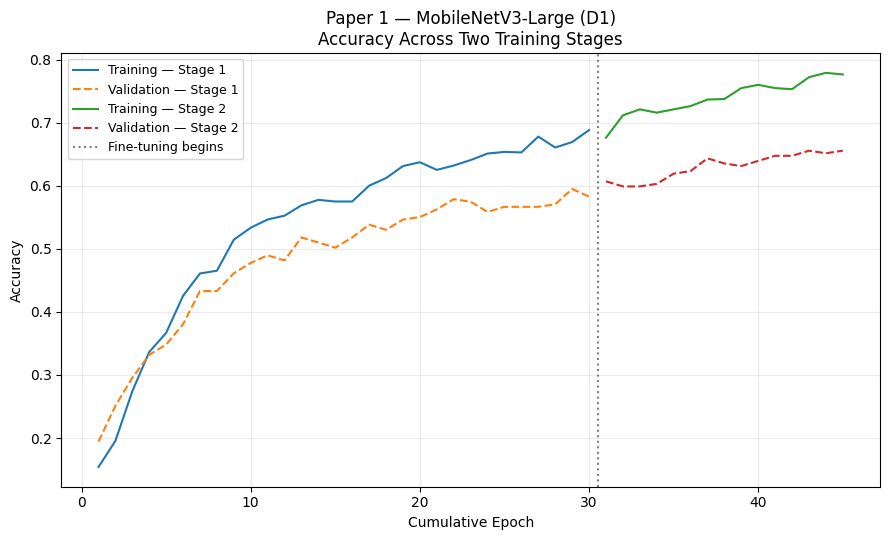

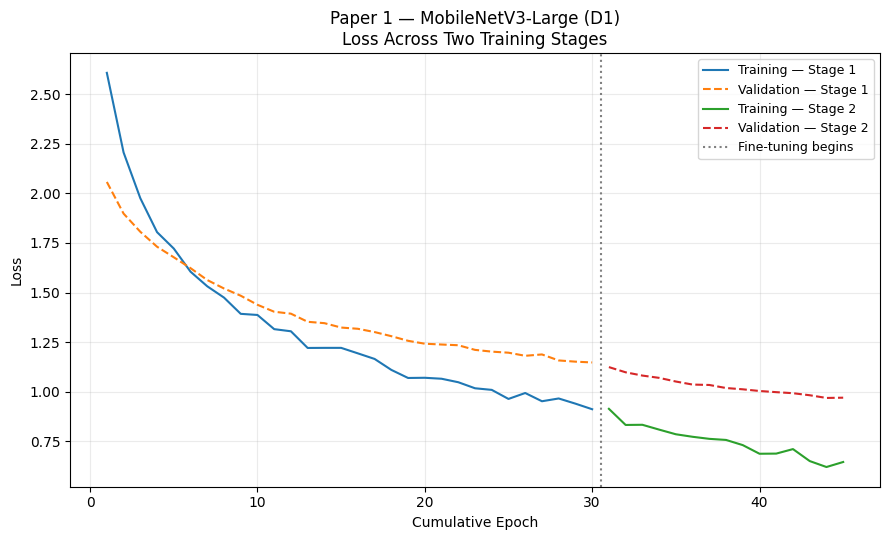


TRAINING CURVE VERIFICATION
Stage 1 epochs: 30
Stage 2 epochs: 15
Total epochs: 45
Stage 1 best validation accuracy: 59.51%
Stage 2 best validation accuracy: 65.59%

SAVED FIGURES
Accuracy: /kaggle/working/Assignment02_Experiment3_D1/figures/paper1_d1_training_accuracy.png
Loss: /kaggle/working/Assignment02_Experiment3_D1/figures/paper1_d1_training_loss.png

Model training: NO
Test predictions: NO

PAPER 1 D1 TRAINING FIGURES: PASSED


In [22]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

stage1 = pd.read_csv(
    RUN_DIR / "stage1_history.csv"
)

stage2 = pd.read_csv(
    RUN_DIR / "stage2_history.csv"
)

required_columns = [
    "accuracy",
    "val_accuracy",
    "loss",
    "val_loss"
]

for history in [stage1, stage2]:
    assert all(
        column in history.columns
        for column in required_columns
    )

    assert np.isfinite(
        history[required_columns].to_numpy()
    ).all()

assert len(stage1) == 30
assert len(stage2) == 15

figures_dir = RUN_DIR / "figures"
figures_dir.mkdir(
    parents=True,
    exist_ok=True
)

stage1_epochs = np.arange(1, 31)
stage2_epochs = np.arange(31, 46)

def save_training_figure(metric, ylabel, filename):
    output = figures_dir / filename

    assert not output.exists(), (
        f"Figure already exists: {output}"
    )

    fig, ax = plt.subplots(figsize=(9, 5.5))

    ax.plot(
        stage1_epochs,
        stage1[metric],
        label="Training — Stage 1"
    )

    ax.plot(
        stage1_epochs,
        stage1["val_" + metric],
        linestyle="--",
        label="Validation — Stage 1"
    )

    ax.plot(
        stage2_epochs,
        stage2[metric],
        label="Training — Stage 2"
    )

    ax.plot(
        stage2_epochs,
        stage2["val_" + metric],
        linestyle="--",
        label="Validation — Stage 2"
    )

    ax.axvline(
        30.5,
        linestyle=":",
        linewidth=1.5,
        color="gray",
        label="Fine-tuning begins"
    )

    ax.set_title(
        "Paper 1 — MobileNetV3-Large (D1)\n"
        + ylabel + " Across Two Training Stages"
    )

    ax.set_xlabel("Cumulative Epoch")
    ax.set_ylabel(ylabel)

    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)

    fig.tight_layout()

    fig.savefig(
        output,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    assert output.is_file()
    assert output.stat().st_size > 0

    return output


accuracy_path = save_training_figure(
    "accuracy",
    "Accuracy",
    "paper1_d1_training_accuracy.png"
)

loss_path = save_training_figure(
    "loss",
    "Loss",
    "paper1_d1_training_loss.png"
)

print("\nTRAINING CURVE VERIFICATION")
print("Stage 1 epochs:", len(stage1))
print("Stage 2 epochs:", len(stage2))
print("Total epochs:", len(stage1) + len(stage2))

print(
    "Stage 1 best validation accuracy:",
    f"{stage1['val_accuracy'].max() * 100:.2f}%"
)

print(
    "Stage 2 best validation accuracy:",
    f"{stage2['val_accuracy'].max() * 100:.2f}%"
)

print("\nSAVED FIGURES")
print("Accuracy:", accuracy_path)
print("Loss:", loss_path)

print("\nModel training: NO")
print("Test predictions: NO")

print("\nPAPER 1 D1 TRAINING FIGURES: PASSED")


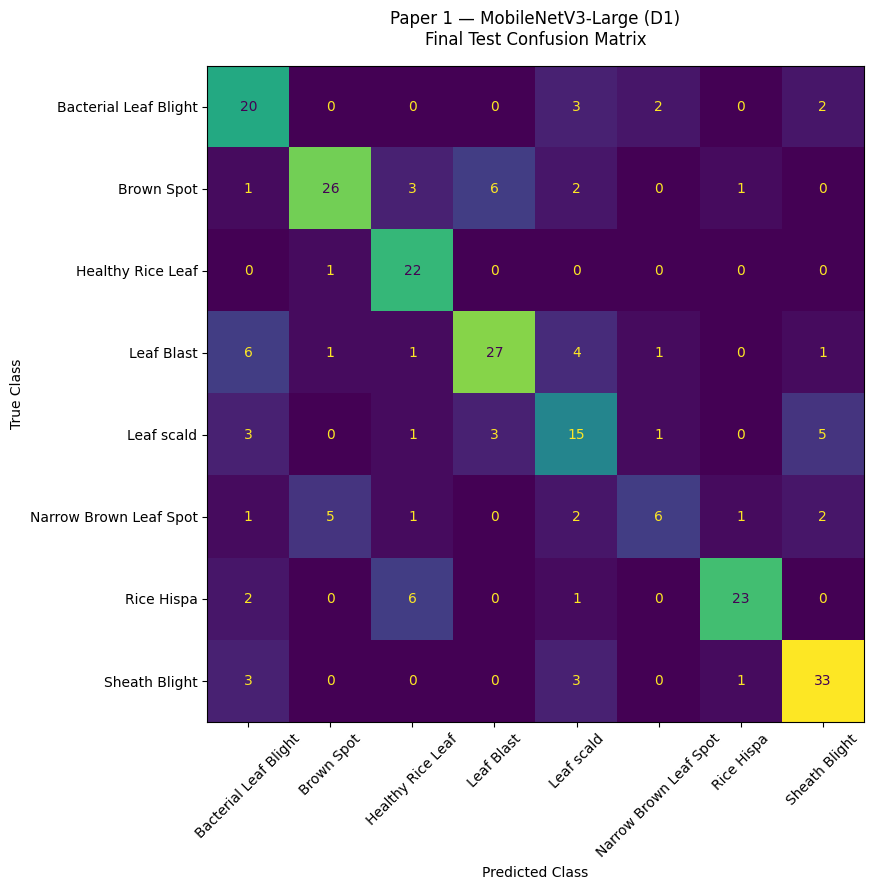

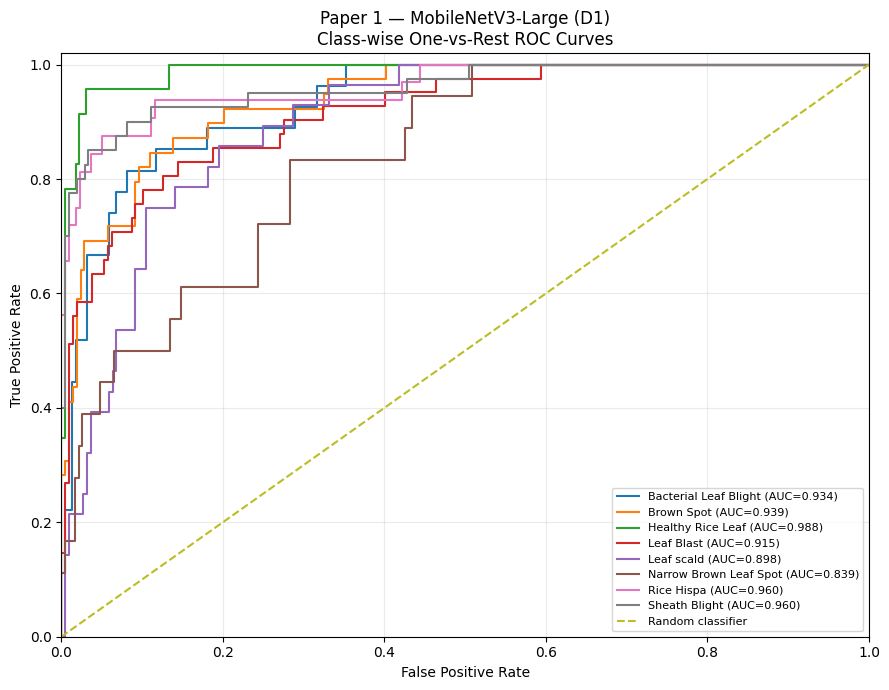


D1 EVALUATION FIGURES
Test images: 248
Correct predictions: 172
Confusion matrix: VERIFIED

CLASS-WISE AUC
Bacterial Leaf Blight: 0.933970
Brown Spot: 0.938658
Healthy Rice Leaf: 0.988213
Leaf Blast: 0.914929
Leaf scald: 0.898214
Narrow Brown Leaf Spot: 0.838647
Rice Hispa: 0.960069
Sheath Blight: 0.960216

Macro OvR AUC: 0.929115
Saved AUC matched: True

SAVED FIGURES
Confusion matrix: /kaggle/working/Assignment02_Experiment3_D1/figures/paper1_d1_confusion_matrix.png
ROC curves: /kaggle/working/Assignment02_Experiment3_D1/figures/paper1_d1_roc_curves.png

Additional training: NO
Additional test inference: NO

PAPER 1 D1 EVALUATION FIGURES: PASSED


In [23]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    roc_auc_score
)

evaluation_dir = (
    RUN_DIR / "final_test_evaluation"
)

figures_dir = RUN_DIR / "figures"

figures_dir.mkdir(
    parents=True,
    exist_ok=True
)

predictions_path = (
    evaluation_dir / "test_predictions.csv"
)

metrics_path = (
    evaluation_dir / "test_metrics.json"
)

confusion_path = (
    evaluation_dir / "confusion_matrix.csv"
)

assert predictions_path.is_file()
assert metrics_path.is_file()
assert confusion_path.is_file()

with metrics_path.open() as f:
    metrics = json.load(f)

predictions = pd.read_csv(
    predictions_path
)

y_true = predictions[
    "true_class_id"
].to_numpy(dtype=np.int32)

y_pred = predictions[
    "predicted_class_id"
].to_numpy(dtype=np.int32)

probabilities = predictions[
    [f"prob_class_{i}" for i in range(8)]
].to_numpy(dtype=np.float64)

class_names = [
    metrics["class_names"][str(i)]
    for i in range(8)
]

assert len(y_true) == 248
assert probabilities.shape == (248, 8)
assert set(y_true) == set(range(8))

assert np.isfinite(probabilities).all()

assert np.allclose(
    probabilities.sum(axis=1),
    1.0,
    atol=1e-5
)

assert np.array_equal(
    np.argmax(probabilities, axis=1),
    y_pred
)

# ---------------------------------
# FIGURE 1: CONFUSION MATRIX
# ---------------------------------

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(8))
)

saved_cm = pd.read_csv(
    confusion_path,
    index_col=0
).to_numpy(dtype=int)

assert np.array_equal(cm, saved_cm)
assert cm.sum() == 248
assert np.trace(cm) == 172

confusion_figure_path = (
    figures_dir /
    "paper1_d1_confusion_matrix.png"
)

assert not confusion_figure_path.exists(), (
    "Confusion matrix figure already exists."
)

fig, ax = plt.subplots(
    figsize=(11, 9)
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

ax.set_title(
    "Paper 1 — MobileNetV3-Large (D1)\n"
    "Final Test Confusion Matrix",
    pad=15
)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("True Class")

fig.tight_layout()

fig.savefig(
    confusion_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ---------------------------------
# FIGURE 2: CLASS-WISE ROC CURVES
# ---------------------------------

roc_figure_path = (
    figures_dir /
    "paper1_d1_roc_curves.png"
)

assert not roc_figure_path.exists(), (
    "ROC figure already exists."
)

fig, ax = plt.subplots(
    figsize=(9, 7)
)

class_auc_values = []

for class_id in range(8):

    binary_true = (
        y_true == class_id
    ).astype(int)

    assert binary_true.sum() > 0
    assert binary_true.sum() < len(y_true)

    fpr, tpr, _ = roc_curve(
        binary_true,
        probabilities[:, class_id]
    )

    class_auc = auc(
        fpr,
        tpr
    )

    class_auc_values.append(
        float(class_auc)
    )

    ax.plot(
        fpr,
        tpr,
        linewidth=1.5,
        label=(
            f"{class_names[class_id]} "
            f"(AUC={class_auc:.3f})"
        )
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

ax.set_title(
    "Paper 1 — MobileNetV3-Large (D1)\n"
    "Class-wise One-vs-Rest ROC Curves"
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.grid(alpha=0.25)

ax.legend(
    fontsize=8,
    loc="lower right"
)

fig.tight_layout()

fig.savefig(
    roc_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ---------------------------------
# FINAL FIGURE VERIFICATION
# ---------------------------------

macro_auc = float(
    np.mean(class_auc_values)
)

assert np.isclose(
    macro_auc,
    metrics["auc_macro_ovr"],
    atol=1e-10
)

assert confusion_figure_path.is_file()
assert roc_figure_path.is_file()

assert confusion_figure_path.stat().st_size > 0
assert roc_figure_path.stat().st_size > 0

print("\nD1 EVALUATION FIGURES")
print("Test images:", len(y_true))
print("Correct predictions:", int(np.trace(cm)))
print("Confusion matrix: VERIFIED")

print("\nCLASS-WISE AUC")

for name, score in zip(
    class_names,
    class_auc_values
):
    print(f"{name}: {score:.6f}")

print("\nMacro OvR AUC:", round(macro_auc, 6))
print("Saved AUC matched: True")

print("\nSAVED FIGURES")
print("Confusion matrix:", confusion_figure_path)
print("ROC curves:", roc_figure_path)

print("\nAdditional training: NO")
print("Additional test inference: NO")

print("\nPAPER 1 D1 EVALUATION FIGURES: PASSED")


In [24]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import hashlib
import json
import platform

import tensorflow as tf
import keras
import pandas as pd
import sklearn

assert RUN_DIR.is_dir()

training_files = [
    "stage1_best.keras",
    "stage1_config.json",
    "stage1_history.csv",
    "stage1_summary.json",
    "stage2_best.keras",
    "stage2_config.json",
    "stage2_history.csv",
    "stage2_summary.json",
    "stage2_checkpoint_audit.json"
]

evaluation_files = [
    "final_test_evaluation/test_metrics.json",
    "final_test_evaluation/test_predictions.csv",
    "final_test_evaluation/confusion_matrix.csv",
    "final_test_evaluation/classification_report.csv",
    "final_test_evaluation/test_evidence_audit.json",
    "figures/paper1_d1_training_accuracy.png",
    "figures/paper1_d1_training_loss.png",
    "figures/paper1_d1_confusion_matrix.png",
    "figures/paper1_d1_roc_curves.png"
]

all_files = training_files + evaluation_files

missing = [
    name
    for name in all_files
    if not (RUN_DIR / name).is_file()
]

assert not missing, f"Missing evidence files: {missing}"

expected_stage1_hash = (
    "651ed0865865956da27648d43c992cf923"
    "064f3d46d9a9bb919f9bc50dffcd11"
)

expected_stage2_hash = (
    "df4efa70bb6dbce74a3f1bf7052f7c1"
    "f5086270c2fba95e8bac1e2559025ceb5"
)

assert hashlib.sha256(
    (RUN_DIR / "stage1_best.keras").read_bytes()
).hexdigest() == expected_stage1_hash

assert hashlib.sha256(
    (RUN_DIR / "stage2_best.keras").read_bytes()
).hexdigest() == expected_stage2_hash

with (RUN_DIR / "final_test_evaluation/test_metrics.json").open() as f:
    metrics = json.load(f)

assert metrics["test_images"] == 248
assert metrics["correct_predictions"] == 172
assert abs(
    metrics["accuracy"] - 172 / 248
) < 1e-10

notes_path = RUN_DIR / "REPRODUCTION_NOTES.txt"

assert not notes_path.exists(), (
    "Reproduction notes already exist. "
    "Inspect them before rerunning."
)

notes = f"""Assignment 02 — Experiment 3 — Dataset D1

MODEL
Paper 1: MobileNetV3-Large
Paper DOI: 10.30871/jaic.v10i1.12033

EXPERIMENTAL DATA
Dataset D1: Rice Leaf Bacterial and Fungal Disease Dataset
Source: https://data.mendeley.com/datasets/hx6f852hw4/2
Training: 1156
Validation: 247
Test: 248
Classes: 8
Frozen manifest SHA256:
3b756d0a4f0326a5e5123284aa884f23fe604d4ace6c56477491acd80ae728d0

IMPLEMENTATION
Input: RGB, 224x224
Backbone: ImageNet-pretrained MobileNetV3-Large
Classifier: GAP, Dense(128, ReLU), Dropout(0.5), Softmax(8)
Framework: TensorFlow {tf.__version__}
Keras: {keras.__version__}
Python: {platform.python_version()}
Pandas: {pd.__version__}
Scikit-learn: {sklearn.__version__}
Seed: 2026

Stage 1: frozen backbone, Adam 0.0001, maximum 30 epochs
Stage 2: last 56 backbone layers selected, BatchNorm
frozen, Adam 0.00001, maximum 15 epochs
Batch size: 32
Checkpoint selection: highest validation accuracy
Early stopping: validation loss, patience 5
Learning-rate reduction: factor 0.5, patience 3

PREPROCESSING
RGB resize to 224x224 using bilinear interpolation.
Training-only rotation, horizontal flip, zoom,
brightness adjustment and Gaussian noise.
Augmentation temporarily uses the 0-1 pixel range
then restores 0-255 inputs for built-in
MobileNetV3 preprocessing.
The paper does not fully specify brightness/noise
implementation details; the notebook records
our independent reconstruction choices.
Validation/test augmentation disabled.

RESULTS
Stage 1 best validation accuracy: 147/247
Stage 2 best validation accuracy: 162/247
Selected checkpoint: stage2_best.keras (epoch 13)
D1 test accuracy: {metrics["accuracy"]:.10f}
Macro precision: {metrics["macro_precision"]:.10f}
Macro recall: {metrics["macro_recall"]:.10f}
Macro F1: {metrics["macro_f1"]:.10f}
Macro OvR AUC: {metrics["auc_macro_ovr"]:.10f}

LIMITATIONS
Cross-dataset independent methodological reconstruction,
not an exact reproduction of the authors' original dataset.
Residual source-image relatedness cannot be excluded
solely by path and duplicate-hash checks.
Published scores are not the results of this experiment.

REPRODUCTION REQUIREMENTS
The full Kaggle notebook must be exported separately as .ipynb.
Original image data and frozen manifest dataset must be
attached to reproduce training or prediction.
Archive manifests contain SHA256 hashes of included files.
"""

notes_path.write_text(notes, encoding="utf-8")


def create_verified_archive(archive_path, relative_files):
    assert not archive_path.exists(), (
        f"Archive already exists: {archive_path}"
    )

    manifest = {}

    with ZipFile(
        archive_path,
        mode="x",
        compression=ZIP_DEFLATED,
        compresslevel=6
    ) as zf:

        for name in relative_files:
            source = RUN_DIR / name
            data = source.read_bytes()

            manifest[name] = {
                "sha256": hashlib.sha256(data).hexdigest(),
                "size_bytes": len(data)
            }

            zf.writestr(name, data)

        zf.writestr(
            "archive_manifest.json",
            json.dumps(manifest, indent=2)
        )

    with ZipFile(archive_path, "r") as zf:
        assert zf.testzip() is None

        stored_manifest = json.loads(
            zf.read("archive_manifest.json")
        )

        assert stored_manifest == manifest

        for name, info in stored_manifest.items():
            content = zf.read(name)

            assert hashlib.sha256(
                content
            ).hexdigest() == info["sha256"]

            assert len(content) == info["size_bytes"]

    return archive_path


training_archive = Path(
    "/kaggle/working/"
    "Assignment02_Experiment3_D1_training_evidence.zip"
)

evaluation_archive = Path(
    "/kaggle/working/"
    "Assignment02_Experiment3_D1_evaluation_evidence.zip"
)

training_archive = create_verified_archive(
    training_archive,
    training_files + ["REPRODUCTION_NOTES.txt"]
)

evaluation_archive = create_verified_archive(
    evaluation_archive,
    evaluation_files + ["REPRODUCTION_NOTES.txt"]
)

print("D1 EVIDENCE ARCHIVE VERIFICATION")
print("Training evidence files:", len(training_files))
print("Evaluation evidence files:", len(evaluation_files))
print("Reproduction notes: INCLUDED")
print("Archive checksums: VERIFIED")
print("ZIP integrity: PASSED")

print("\nARCHIVES")
for path in [training_archive, evaluation_archive]:
    print(path)
    print(
        "Size (MB):",
        round(path.stat().st_size / (1024 ** 2), 2)
    )

print("\nOriginal checkpoints preserved: YES")
print("Additional training: NO")
print("Additional inference: NO")

print("\nPAPER 1 D1 EVIDENCE ARCHIVES: PASSED")


D1 EVIDENCE ARCHIVE VERIFICATION
Training evidence files: 9
Evaluation evidence files: 9
Reproduction notes: INCLUDED
Archive checksums: VERIFIED
ZIP integrity: PASSED

ARCHIVES
/kaggle/working/Assignment02_Experiment3_D1_training_evidence.zip
Size (MB): 41.5
/kaggle/working/Assignment02_Experiment3_D1_evaluation_evidence.zip
Size (MB): 0.79

Original checkpoints preserved: YES
Additional training: NO
Additional inference: NO

PAPER 1 D1 EVIDENCE ARCHIVES: PASSED
